# Predicting Online Purchases — PRD 3.5
### DSA211 · Prediction-only · EDA-grounded final presentation

**Research question.** How accurately can browsing-session characteristics distinguish sessions ending in a purchase (`Revenue=1`), and which course-based classifier has the highest **mean five-fold training ROC-AUC**?

**Design.** Six all-17 first-pass diagnostic models → six operational 16-predictor baselines → 41 historical development trials → two independently pruned classification trees → six-way final comparison. Show **only 26 EDA-/course-motivated original-family trials** in four independently annotated tables (7 Logistic, 7 LDA, 7 Gaussian NB, 5 Bernoulli NB), alongside four full/pruned tree comparisons. Preserve all complete historical evidence.

**Evidence provenance.** This is an **editorial presentation of the fully executed and independently audited PRD v3.4 results**, not a new modelling experiment. Embedded results are reformatted from the frozen [v3.4 trial ledger](artifacts/prd_v3_4/all_attempts_ledger.csv) and [tree comparisons](artifacts/prd_v3_4/tree_full_vs_selected.csv). **No models were refitted to create v3.5.** The original [executed v3.4 notebook](archive/versions/v3.4/online_shoppers_prd_v3_4.ipynb) and [audit](artifacts/prd_v3_4/independent_training_audit.json) remain unchanged. The retained computational cells allow independent reproducibility; a voluntary full rerun writes only to the isolated `artifacts/prd_v3_5/` directory.

**Selection criterion.** A challenger was retained only when its gain in mean five-fold ROC-AUC **strictly exceeded its own five-fold AUC SE**. This original heuristic is not a formal significance test. Later v3.2/v3.3 candidates used recorded fixed anchor comparisons; all historical decisions remain unchanged.

**Secondary illustration.** An assumed S$3 contact cost, 30% conditional upsell success and S$50 gross margin yield an illustrative 0.20 cutoff; this is **not** evidence of causal uplift or probability calibration.

**Active specification.** [PRD v3.5](PRD_v3.5.md). **Source protocol:** [PRD v3.4](archive/versions/v3.4/PRD_v3.4.md).
**Supplementary EDA incorporated:** All six substantive training-only supplementary investigations are now embedded under Sections 2–4 with their original outputs. Main family tables show metrics only; iteration explanations appear immediately after each table. The pruned Entropy tree illustration is presented within the tree section, before the six-family winner is chosen.


## 0. Fixed protocol and reporting boundary

**Data.** The UCI dataset contains 12,330 sessions; 9,864 training and 2,466 historically reused reserved observations, with the original seed-42 stratified 80/20 split. Sixteen operational predictors exclude `PageValues` because its availability at decision time is uncertain, **not** because leakage has been established. All candidate comparisons use the original five shared stratified training folds.

**Historical model fitting.** Train-fold-safe encoding, medians, scaling, feature selection and tuning were implemented in v3.4. Selection and evaluation results are **reused without recomputation** for this presentation. Earlier v3.2/v3.3 probes were anchored, while v3.4 L13/L14/D15 followed their recorded sequential rule. All 41 trials, 51 scored designs, 255 fold scores and 37 nonbaseline decisions remain available.

**Interpretation.** ROC-AUC measures ranking; average precision highlights minority-class ranking. Neither establishes calibration, causal impact or profitability. The previously consulted reserved set is **not a pristine holdout**.

**Reporting view.** Display the shortlists from PRD v3.5 (7/7/7/5) with EDA rationale and historical outcome, plus separate all-17, operational-baseline, tree-pruning and six-finalist sections. Omitted trials are *hidden from the main display only*, not deleted.

In [1]:
from pathlib import Path
import hashlib, json, warnings, platform, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, scipy, sklearn
from scipy import stats
from scipy.special import logsumexp
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
import statsmodels.api as sm
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, log_loss, roc_curve, confusion_matrix

RUN_START=time.perf_counter()
SEED=42; TEST_FRAC=.20; K=5
TARGET='Revenue'
NUMERIC_ALL=['Administrative','Administrative_Duration','Informational','Informational_Duration',
 'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay']
CAT=['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType']
ACTIVITY=['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration']
NUMERIC_SAFE=[x for x in NUMERIC_ALL if x!='PageValues']
ALL=NUMERIC_ALL+CAT+['Weekend']; SAFE=NUMERIC_SAFE+CAT+['Weekend']
EXPECTED=set(ALL+[TARGET])
root_candidates=[Path('data/uci_468.csv'),Path('../data/uci_468.csv')]
data_path=next((p for p in root_candidates if p.is_file()),None)
if data_path is None: raise FileNotFoundError('Run from repository root or a direct child directory; expected data/uci_468.csv')
ROOT=data_path.parent.parent if data_path.parent.name=='data' else data_path.parent.parent
ARTIFACTS=ROOT/'artifacts'; ARTIFACTS.mkdir(exist_ok=True)
WORK=ROOT/'work'; WORK.mkdir(exist_ok=True)
PROGRESS_LOG=WORK/'baseline_progress.jsonl'; PROGRESS_LOG.write_text('')
def mark_progress(candidate,fold,event,**details):
    record={'candidate':candidate,'fold':fold,'event':event,'elapsed_seconds':round(time.perf_counter()-RUN_START,3),**details}
    with PROGRESS_LOG.open('a') as f: f.write(json.dumps(record,default=str)+'\n')
print(f'Python {platform.python_version()} | pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__}')
print('Operational selection uses mean five-fold training ROC-AUC; AP and fold variation are supporting evidence. Threshold diagnostics use only winner training OOF predictions.')


Python 3.12.15 | pandas 3.0.6 | NumPy 2.5.4 | SciPy 1.18.1 | scikit-learn 1.9.1
Operational selection uses mean five-fold training ROC-AUC; AP and fold variation are supporting evidence. Threshold diagnostics use only winner training OOF predictions.


## 1. Data quality and split

**Purpose.** Verify source completeness and establish training/holdout membership.

**Method.** Check missingness, outcome balance and duplicates; preserve all 12,330 sessions. Use training rows only for EDA, candidate selection and threshold comparisons.


In [2]:
raw=pd.read_csv(data_path); raw.insert(0,'_row_id',np.arange(len(raw),dtype=int))
source_hash=hashlib.sha256(data_path.read_bytes()).hexdigest()
if raw.shape!=(12330,19): raise ValueError(f'Expected 12,330 rows and 18 source columns, found {raw.shape}')
if set(raw.columns)-{'_row_id'} != EXPECTED: raise ValueError(f'Unexpected source columns: {sorted((set(raw.columns)-{"_row_id"}) ^ EXPECTED)}')
if raw[TARGET].isna().any() or not set(raw[TARGET].unique()).issubset({0,1,False,True}): raise ValueError('Revenue must be complete binary 0/1')
raw[TARGET]=raw[TARGET].astype(int)
if raw[NUMERIC_ALL].isna().any().any() or not np.isfinite(raw[NUMERIC_ALL].to_numpy(float)).all(): raise ValueError('Numeric source predictors must be complete and finite')
blank=raw[CAT].astype('string').apply(lambda s:s.str.strip().eq('').sum())
missing=raw.drop(columns='_row_id').isna().sum()
if missing.any() or blank.any(): raise ValueError('Unexpected missing values or blank nominal markers; inspect source before modelling')
if raw['Weekend'].isna().any() or not set(raw['Weekend'].unique()).issubset({0,1,False,True}): raise ValueError('Weekend must be complete binary 0/1')
quality=pd.DataFrame({'dtype':raw.drop(columns='_row_id').dtypes.astype(str),'missing':missing,
                      'blank nominal':blank.reindex(missing.index,fill_value=0),'unique':raw.drop(columns='_row_id').nunique()})
print('Source shape (rows, columns):',(len(raw),len(raw.columns)-1),'SHA-256:',source_hash)
print('Duplicate excess / unique full rows:',int(raw.duplicated(subset=raw.columns.drop('_row_id')).sum()),'/',raw.drop(columns='_row_id').drop_duplicates().shape[0])
print(f'Missing: {int(missing.sum())}; blank nominal: {int(blank.sum())}')
display(raw[TARGET].value_counts().sort_index().rename_axis(TARGET).to_frame('sessions').assign(share=lambda d:d.sessions/len(raw)))
dup=raw.loc[raw.duplicated(subset=raw.columns.drop('_row_id'),keep='first')]
print(f'Excess duplicates: {len(dup)}; duplicate outcomes:',dup[TARGET].value_counts().sort_index().to_dict())

train_ids,test_ids=train_test_split(raw['_row_id'].to_numpy(),test_size=TEST_FRAC,
    stratify=raw[TARGET].to_numpy(),random_state=SEED)
train_ids=np.sort(train_ids); test_ids=np.sort(test_ids)
pd.DataFrame({'row_id':train_ids,'partition':'train'}).to_csv(ARTIFACTS/'train_row_ids.csv',index=False)
pd.DataFrame({'row_id':test_ids,'partition':'test'}).to_csv(ARTIFACTS/'test_row_ids.csv',index=False)
train=raw.set_index('_row_id').loc[train_ids].copy()
y_train=train.pop(TARGET).astype(int)
X_train=train[ALL].copy()
X_train[CAT]=X_train[CAT].astype('string')
X_train['Weekend']=X_train['Weekend'].astype(int)
del raw,dup
cv=StratifiedKFold(n_splits=K,shuffle=True,random_state=SEED)
FOLD_INDICES=list(cv.split(np.zeros(len(y_train)),y_train))
fold_map=[]
for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
    fold_map += [{'row_id':int(X_train.index[i]),'fold':fold,'role':'fit'} for i in fit_idx]
    fold_map += [{'row_id':int(X_train.index[i]),'fold':fold,'role':'validation'} for i in val_idx]
pd.DataFrame(fold_map).to_csv(ARTIFACTS/'cv_fold_row_ids.csv',index=False)
print(f'Training={len(X_train):,}; holdout IDs recorded={len(test_ids):,}; purchases={y_train.sum():,} ({y_train.mean():.2%}).')

print(f'Interpretation: training prevalence is {y_train.mean():.2%}, so accuracy alone can reward predicting no purchase. Preserve 125 identical rows, but note dependence risk across folds.')


Source shape (rows, columns): (12330, 18) SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Duplicate excess / unique full rows: 125 / 12205
Missing: 0; blank nominal: 0


,sessions,share
Revenue,,
0,10422,0.845255
1,1908,0.154745


Excess duplicates: 125; duplicate outcomes: {0: 125}


Training=9,864; holdout IDs recorded=2,466; purchases=1,526 (15.47%).
Interpretation: training prevalence is 15.47%, so accuracy alone can reward predicting no purchase. Preserve 125 identical rows, but note dependence risk across folds.


## 2. Numerical EDA

**Purpose.** Identify skew and excess zeros.

**Method.** Display median, zero share and skewness, with representative histograms.

**Implication.** Test log1p for long tails and fold-fitted presence indicators for zero-heavy activity.


,median,zero share,skew
Administrative,1.000,0.467,1.967
Administrative_Duration,8.000,0.477,5.679
Informational,0.000,0.785,4.142
Informational_Duration,0.000,0.805,7.702
ProductRelated,18.000,0.003,4.372
ProductRelated_Duration,600.537,0.062,8.009
BounceRates,0.003,0.448,2.924
ExitRates,0.025,0.006,2.130
PageValues,0.000,0.778,6.187
SpecialDay,0.000,0.897,3.261


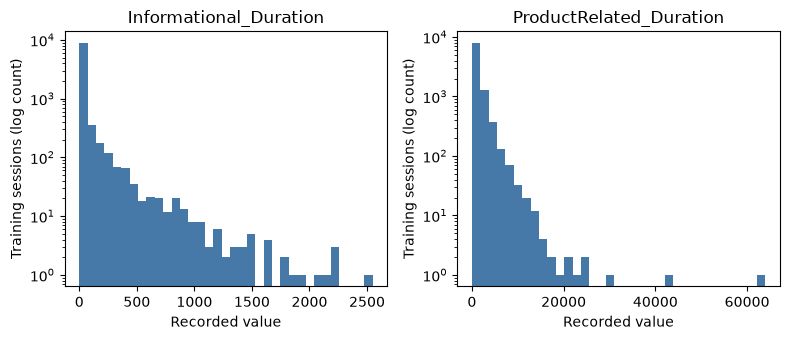

Interpretation: Informational has 78.5% zeros, Informational_Duration 80.5% zeros, and ProductRelated_Duration skew=8.01. These motivate, but do not validate, presence and log1p trials.


In [3]:
Xtr=X_train; ytr=y_train
num_summary=pd.DataFrame({'median':Xtr[NUMERIC_ALL].median(),'zero share':Xtr[NUMERIC_ALL].eq(0).mean(),
                          'skew':Xtr[NUMERIC_ALL].skew(),'buyer median':Xtr.loc[ytr.eq(1),NUMERIC_ALL].median(),
                          'nonbuyer median':Xtr.loc[ytr.eq(0),NUMERIC_ALL].median()})
display(num_summary[['median','zero share','skew']].round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes.flat,['Informational_Duration','ProductRelated_Duration']):
    ax.hist(Xtr[col],bins=35,log=True,color='#4779a8'); ax.set(title=col,xlabel='Recorded value',ylabel='Training sessions (log count)')
plt.tight_layout(); plt.show()
long_tail=num_summary.loc[ACTIVITY,'skew']

print(f'Interpretation: Informational has {num_summary.loc["Informational","zero share"]:.1%} zeros, Informational_Duration {num_summary.loc["Informational_Duration","zero share"]:.1%} zeros, and ProductRelated_Duration skew={num_summary.loc["ProductRelated_Duration","skew"]:.2f}. These motivate, but do not validate, presence and log1p trials.')


### 2.1 Zero-versus-positive activity and positive intensity

The zero/positive comparison and positive-value quantile bins below informed the presence-indicator and log/intensity experiments. The purchase rates are **unadjusted training EDA**, not proof that presence causes purchasing or improves multivariable prediction.

In [26]:
# Originally executed as training-only supplementary EDA. Saved outputs below are reproduced unchanged.
# Reuse the identical seed-42 training partition from the current notebook.
X=Xtr; y=ytr; NUMERIC=NUMERIC_ALL
rows=[]; details=[]
for col in ACTIVITY:
    pos=X[col]>0; rows.append({'feature':col,'skew':X[col].skew(),'zero_share':(~pos).mean(),'zero_n':(~pos).sum(),'zero_buyer_rate':y[~pos].mean(),'positive_n':pos.sum(),'positive_buyer_rate':y[pos].mean()})
    vals=X.loc[pos,col]
    for q,v in vals.quantile([.25,.5,.75,.9]).items(): details.append({'feature':col,'evidence':'positive quantile','level':q,'value':v})
    bins=pd.qcut(vals,4,duplicates='drop')
    t=pd.DataFrame({'bin':bins,'x':vals,'buyer':y[pos]}).groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyer_rate=('buyer','mean'))
    for b,r in t.iterrows(): details.append({'feature':col,'evidence':'positive intensity bin','level':str(b),'n':int(r.n),'value':r.mean_x,'buyer_rate':r.buyer_rate})
ACTIVITY_SUMMARY=pd.DataFrame(rows).set_index('feature'); display(ACTIVITY_SUMMARY.round(4)); display(pd.DataFrame(details).round(4))
for col in ['Informational','Informational_Duration','Administrative','Administrative_Duration']:
    r=ACTIVITY_SUMMARY.loc[col]
    print(f"{col}: skew={r['skew']:.2f}, zero={r['zero_share']:.1%}; buyer rate is {r['zero_buyer_rate']:.1%} at zero and {r['positive_buyer_rate']:.1%} above zero.")
eligible=ACTIVITY_SUMMARY[(ACTIVITY_SUMMARY['skew'].abs()>2)&(ACTIVITY_SUMMARY['zero_share']>=.50)].index.tolist()
print('Under the predeclared training EDA rule (|skew|>2 and zero share >=50%), candidate activity columns for fold-fitted presence indicators:', eligible or 'none')
print('Positive-only bins are broadly increasing for Informational and ProductRelated_Duration, but Administrative_Duration is uneven; bins are descriptive and do not establish conditional effects.')

,skew,zero_share,zero_n,zero_buyer_rate,positive_n,positive_buyer_rate
feature,,,,,,
Administrative,1.9668,0.4671,4607,0.0873,5257,0.2138
Administrative_Duration,5.6787,0.4771,4706,0.0901,5158,0.2136
Informational,4.1424,0.7854,7747,0.1330,2117,0.2343
Informational_Duration,7.7018,0.8047,7938,0.1349,1926,0.2362
ProductRelated,4.3718,0.0027,27,0.0741,9837,0.1549
ProductRelated_Duration,8.0091,0.0620,612,0.0131,9252,0.1641


,feature,evidence,level,value,n,buyer_rate
0,Administrative,positive quantile,0.25,2.0000,NaN,NaN
1,Administrative,positive quantile,0.5,3.0000,NaN,NaN
2,Administrative,positive quantile,0.75,6.0000,NaN,NaN
3,Administrative,positive quantile,0.9,9.0000,NaN,NaN
4,Administrative,positive intensity bin,"(0.999, 2.0]",1.4501,1962.0,0.2023
5,Administrative,positive intensity bin,"(2.0, 3.0]",3.0000,732.0,0.1858
6,Administrative,positive intensity bin,"(3.0, 6.0]",4.8148,1458.0,0.2181
7,Administrative,positive intensity bin,"(6.0, 27.0]",9.7738,1105.0,0.2471
8,Administrative_Duration,positive quantile,0.25,39.3250,NaN,NaN
9,Administrative_Duration,positive quantile,0.5,87.7250,NaN,NaN


Informational: skew=4.14, zero=78.5%; buyer rate is 13.3% at zero and 23.4% above zero.
Informational_Duration: skew=7.70, zero=80.5%; buyer rate is 13.5% at zero and 23.6% above zero.
Administrative: skew=1.97, zero=46.7%; buyer rate is 8.7% at zero and 21.4% above zero.
Administrative_Duration: skew=5.68, zero=47.7%; buyer rate is 9.0% at zero and 21.4% above zero.
Under the predeclared training EDA rule (|skew|>2 and zero share >=50%), candidate activity columns for fold-fitted presence indicators: ['Informational', 'Informational_Duration']
Positive-only bins are broadly increasing for Informational and ProductRelated_Duration, but Administrative_Duration is uneven; bins are descriptive and do not establish conditional effects.


## 3. Categorical EDA

**Purpose.** Compare observed buying rates across nominal levels.

**Method.** Summarise sparsity and show Month/VisitorType rates on training rows.

**Implication.** Encode nominal levels in each CV fit; avoid over-interpreting small groups.


In [4]:
cat_summary=[]
for col in CAT:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    cat_summary.append({'feature':col,'levels':len(tab),'small levels <50':int((tab.sessions<50).sum()),
      'small-level sessions':int(tab.loc[tab.sessions<50,'sessions'].sum()),
      'buyer-rate range':f"{tab.buyer_rate.min():.1%}–{tab.buyer_rate.max():.1%}"})
display(pd.DataFrame(cat_summary).set_index('feature')[['levels','small levels <50','buyer-rate range']])
for col in ['Month','VisitorType']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).sort_values('sessions',ascending=False)
    print(f'Training group counts and observed buyer rates: {col}')
    display(tab[['sessions','buyer_rate']].round(3))
rare=[]
for col in ['TrafficType','Browser','Region']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    small=tab[tab.sessions<50]
    rare.append({'feature':col,'levels below n=50':len(small),'total levels':len(tab),
                 'rare-cell rate range':f"{small.buyer_rate.min():.1%}–{small.buyer_rate.max():.1%}" if len(small) else 'none'})
vtm=Xtr.assign(Revenue=ytr).groupby(['VisitorType','Month'],observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).reset_index()
special=Xtr.assign(Revenue=ytr).groupby('SpecialDay',observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))

print(f'Interpretation: {int((Xtr.Browser.value_counts()<50).sum())} Browser and {int((Xtr.TrafficType.value_counts()<50).sum())} TrafficType levels have fewer than 50 training rows. Fold-fitted pooling is a hypothesis, not a guaranteed gain; all six categories remain nominal.')


,levels,small levels <50,buyer-rate range
feature,,,
Month,10,0,1.4%–24.8%
OperatingSystems,8,3,10.6%–25.0%
Browser,13,4,0.0%–42.9%
Region,9,0,14.2%–17.0%
TrafficType,20,9,0.0%–33.3%
VisitorType,3,0,14.0%–24.7%


Training group counts and observed buyer rates: Month


,sessions,buyer_rate
Month,,
May,2703,0.108
Nov,2360,0.248
Mar,1538,0.103
Dec,1391,0.132
Oct,444,0.221
Sep,368,0.204
Jul,344,0.134
Aug,342,0.178
June,228,0.101


Training group counts and observed buyer rates: VisitorType


,sessions,buyer_rate
VisitorType,,
Returning_Visitor,8443,0.140
New_Visitor,1347,0.247
Other,74,0.176


Interpretation: 4 Browser and 9 TrafficType levels have fewer than 50 training rows. Fold-fitted pooling is a hypothesis, not a guaranteed gain; all six categories remain nominal.


### 3.1 VisitorType × Month purchase rates and support

Use the session counts and rates together: four observed month-by-visitor cells have fewer than 50 sessions. This was used to avoid an unsupported VisitorType × Month interaction despite visible marginal variation.

Month,Aug,Dec,Feb,Jul,June,Mar,May,Nov,Oct,Sep
VisitorType,,,,,,,,,,
New_Visitor,56,268,1,40,22,183,254,326,105,92
Other,0,54,0,0,0,0,0,20,0,0
Returning_Visitor,286,1069,145,304,206,1355,2449,2014,339,276


Month,Aug,Dec,Feb,Jul,June,Mar,May,Nov,Oct,Sep
VisitorType,,,,,,,,,,
New_Visitor,0.321,0.231,0.000,0.150,0.227,0.137,0.264,0.307,0.229,0.283
Other,NaN,0.204,NaN,NaN,NaN,NaN,NaN,0.100,NaN,NaN
Returning_Visitor,0.150,0.104,0.014,0.132,0.087,0.099,0.092,0.240,0.218,0.178


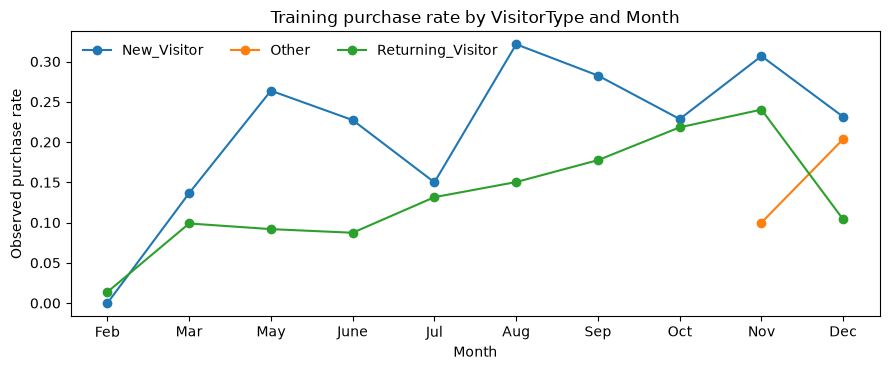

Cells below 50 sessions: 4


,VisitorType,Month,sessions,buyers,purchase_rate
2,New_Visitor,Feb,1,0,0.000
11,Other,Nov,20,2,0.100
4,New_Visitor,June,22,5,0.227
3,New_Visitor,Jul,40,6,0.150


Across supported months (n>=50), purchase-rate ranges by visitor type:


,min,max,count
VisitorType,,,
New_Visitor,0.137,0.321,7
Other,0.204,0.204,1
Returning_Visitor,0.014,0.240,10


New_Visitor: supported-month purchase rates span 13.7%–32.1% across 7 months.
Other: supported-month purchase rates span 20.4%–20.4% across 1 months.
Returning_Visitor: supported-month purchase rates span 1.4%–24.0% across 10 months.
The observed month variation is descriptive and 4 cells are sparse; do not add a VisitorType × Month recipe from this evidence alone.


In [27]:
# Originally executed as training-only supplementary EDA. Saved outputs below are reproduced unchanged.
cross=X.assign(Revenue=y).groupby(['VisitorType','Month'],observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean')).reset_index()
display(cross.pivot(index='VisitorType',columns='Month',values='sessions').fillna(0).astype(int)); display(cross.pivot(index='VisitorType',columns='Month',values='purchase_rate').round(3))
fig,ax=plt.subplots(figsize=(9,3.8))
month_order=['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec']
for v,g in cross.groupby('VisitorType'):
    g=g.assign(Month=pd.Categorical(g.Month,categories=month_order,ordered=True)).sort_values('Month')
    ax.plot(g.Month.astype(str),g.purchase_rate,marker='o',label=v)
ax.set(title='Training purchase rate by VisitorType and Month',xlabel='Month',ylabel='Observed purchase rate'); ax.legend(frameon=False,ncol=3); plt.tight_layout(); plt.show()
small=cross[cross.sessions<50].sort_values('sessions'); print('Cells below 50 sessions:',len(small)); display(small.round(3))
supported=cross[cross.sessions>=50].groupby('VisitorType').purchase_rate.agg(['min','max','count'])
print('Across supported months (n>=50), purchase-rate ranges by visitor type:')
display(supported.round(3))
for visitor,r in supported.iterrows(): print(f"{visitor}: supported-month purchase rates span {r['min']:.1%}–{r['max']:.1%} across {int(r['count'])} months.")
print('The observed month variation is descriptive and 4 cells are sparse; do not add a VisitorType × Month recipe from this evidence alone.')

### 3.2 Rare category levels

The full observed TrafficType, Browser and Region level counts are shown below. Thirteen of 42 levels have fewer than 50 sessions, which motivates cautious encoding and demonstrates why extreme small-cell rates are unreliable.

In [28]:
# Originally executed as training-only supplementary EDA. Saved outputs below are reproduced unchanged.
rr=[]
for col in ['TrafficType','Browser','Region']:
    t=X.assign(Revenue=y).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean'))
    for level,r in t.iterrows(): rr.append({'feature':col,'level':str(level),'sessions':int(r.sessions),'buyers':int(r.buyers),'purchase_rate':r.purchase_rate,'support':'<50' if r.sessions<50 else '>=50'})
RARE_LEVELS=pd.DataFrame(rr).sort_values(['feature','sessions','level']); display(RARE_LEVELS.round(4))
sparse=RARE_LEVELS[RARE_LEVELS.support=='<50']
print(f"{len(sparse)} of {len(RARE_LEVELS)} levels have <50 sessions. Among these, observed rates range {sparse.purchase_rate.min():.1%}–{sparse.purchase_rate.max():.1%}; examples at the extremes are highly uncertain. Keep levels nominal; this evidence does not justify arbitrary pooling.")

,feature,level,sessions,buyers,purchase_rate,support
28,Browser,9,1,0,0.0000,<50
30,Browser,11,5,1,0.2000,<50
31,Browser,12,7,3,0.4286,<50
26,Browser,7,36,2,0.0556,<50
32,Browser,13,52,13,0.2500,>=50
22,Browser,3,83,4,0.0482,>=50
27,Browser,8,107,12,0.1121,>=50
29,Browser,10,135,29,0.2148,>=50
25,Browser,6,140,16,0.1143,>=50
24,Browser,5,382,70,0.1832,>=50


13 of 42 levels have <50 sessions. Among these, observed rates range 0.0%–42.9%; examples at the extremes are highly uncertain. Keep levels nominal; this evidence does not justify arbitrary pooling.


### 3.3 SpecialDay score versus positive presence

The numerical score is zero in 89.7% of training rows. These exact-score and zero-versus-positive rates informed the historical SpecialDay coding hypotheses—even though those trials are not among the final seven displayed per family.

,SpecialDay,sessions,buyers,purchase_rate
0,0.0,8850,1466,0.1656
1,0.2,142,13,0.0915
2,0.4,189,9,0.0476
3,0.6,286,26,0.0909
4,0.8,271,6,0.0221
5,1.0,126,6,0.0476


,group,sessions,buyers,rate
0,zero,8850,1466,0.1656
1,positive,1014,60,0.0592


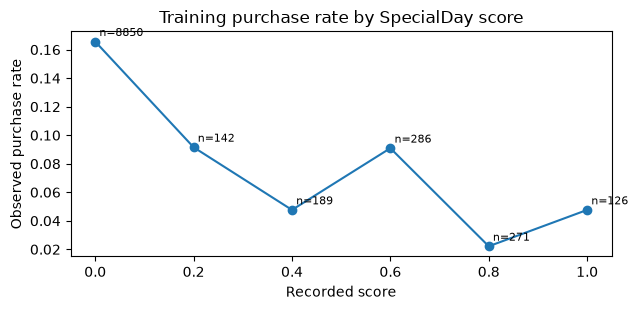

The zero/positive rates are 16.6% and 5.9%; positive-score values are not monotone in rate across their supports. This supports considering presence as a simple representation for the NB revision review, while retaining the numeric baseline.


In [29]:
# Originally executed as training-only supplementary EDA. Saved outputs below are reproduced unchanged.
sp=X.assign(Revenue=y).groupby('SpecialDay',observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean')).reset_index().sort_values('SpecialDay'); display(sp.round(4))
pos=X.SpecialDay>0; special_binary=pd.DataFrame([{'group':'zero','sessions':(~pos).sum(),'buyers':y[~pos].sum(),'rate':y[~pos].mean()},{'group':'positive','sessions':pos.sum(),'buyers':y[pos].sum(),'rate':y[pos].mean()}]); display(special_binary.round(4))
fig,ax=plt.subplots(figsize=(6.5,3.2)); ax.plot(sp.SpecialDay,sp.purchase_rate,marker='o')
for r in sp.itertuples(): ax.annotate(f'n={r.sessions}',(r.SpecialDay,r.purchase_rate),xytext=(3,4),textcoords='offset points',fontsize=8)
ax.set(title='Training purchase rate by SpecialDay score',xlabel='Recorded score',ylabel='Observed purchase rate'); plt.tight_layout(); plt.show()
print(f"The zero/positive rates are {special_binary.loc[0,'rate']:.1%} and {special_binary.loc[1,'rate']:.1%}; positive-score values are not monotone in rate across their supports. This supports considering presence as a simple representation for the NB revision review, while retaining the numeric baseline.")

## 4. Predictor relationships and assumptions

**Purpose.** Assess dependence and departure from Gaussian shapes.

**Method.** Check selected within-class correlations and Q–Q plots.

**Implication.** Diagnostics motivate candidates; CV, not visual assumptions alone, evaluates performance.


BounceRates/ExitRates correlations are 0.915 for nonbuyers and 0.723 for buyers; ProductRelated/ProductRelated_Duration are 0.839 and 0.896. These selected differences do not establish unequal full covariance matrices.


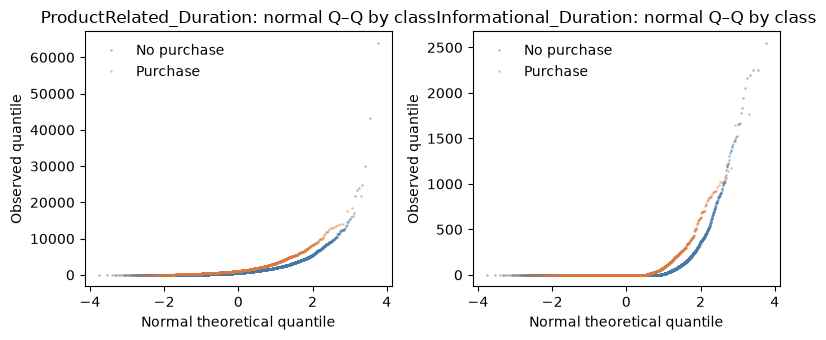

In [5]:
NUM_SAFE=[c for c in NUMERIC_ALL if c!='PageValues']+['Weekend']
for cls in [0,1]:
    corr=Xtr.loc[ytr.eq(cls),NUM_SAFE].corr().abs()
    pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().sort_values(ascending=False).head(5)
print('BounceRates/ExitRates correlations are {:.3f} for nonbuyers and {:.3f} for buyers; ProductRelated/ProductRelated_Duration are {:.3f} and {:.3f}. These selected differences do not establish unequal full covariance matrices.'.format(
 Xtr.loc[ytr.eq(0),['BounceRates','ExitRates']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['BounceRates','ExitRates']].corr().iloc[0,1],
 Xtr.loc[ytr.eq(0),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1]))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes,['ProductRelated_Duration','Informational_Duration']):
    for cls,label,color in [(0,'No purchase','#4779a8'),(1,'Purchase','#d97941')]:
        vals=Xtr.loc[ytr.eq(cls),col].to_numpy()
        (osm,osr),_=stats.probplot(vals,dist='norm',fit=True)
        ax.plot(osm,osr,'.',ms=2,alpha=.35,label=label,color=color)
    ax.set(title=f'{col}: normal Q–Q by class',xlabel='Normal theoretical quantile',ylabel='Observed quantile'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

def marginal_elogit(col, bins=8):
    z=pd.DataFrame({'x':Xtr[col],'buyer':ytr}); z['bin']='zero'; positive=z.x.gt(0)
    if positive.any(): z.loc[positive,'bin']=pd.qcut(z.loc[positive,'x'],bins,duplicates='drop').astype(str)
    out=z.groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyers=('buyer','sum'),rate=('buyer','mean')).reset_index()
    out['empirical_logit']=np.log((out.buyers+.5)/(out.n-out.buyers+.5))
    return out.sort_values('mean_x')


### 4.1 Predictor availability at the proposed intervention time

The original dataset does not include timestamps proving when each session metric becomes known. This training-source assessment supports excluding `PageValues` as a **timing precaution**, not as a demonstrated instance of leakage; other inputs also require a deployment-time audit.

In [30]:
# Originally executed as training-only supplementary EDA. Saved outputs below are reproduced unchanged.
timing=[
('Administrative','Session count of administrative pages','Accumulator may evolve until session end','Unverified'),('Administrative_Duration','Time on administrative pages','Accumulator may evolve until session end','Unverified'),('Informational','Session count of informational pages','Accumulator may evolve until session end','Unverified'),('Informational_Duration','Time on informational pages','Accumulator may evolve until session end','Unverified'),('ProductRelated','Session count of product pages','Accumulator may evolve until session end','Unverified'),('ProductRelated_Duration','Time on product pages','Accumulator may evolve until session end','Unverified'),('BounceRates','Analytics bounce measure','May depend on session completion/processing','Timing unknown'),('ExitRates','Analytics exit measure','May depend on page exit/session completion','Timing unknown'),('PageValues','Analytics page value related to transaction likelihood/value','Could reflect completed-session information','Possible downstream timing; exclude operationally'),('SpecialDay','Calendar proximity score','Calendar-derived','Likely known; unverified'),('Month','Visit month','Calendar-derived','Likely known; unverified'),('OperatingSystems','Operating system category','Potentially observed at arrival','Likely early; unverified'),('Browser','Browser category','Potentially observed at arrival','Likely early; unverified'),('Region','Visitor region category','Geolocation/analytics processing may vary','Unverified'),('TrafficType','Traffic source category','Attribution timing may vary','Unverified'),('VisitorType','New/returning visitor category','May rely on cookies/prior-visit linkage','Unverified'),('Weekend','Weekend indicator','Calendar-derived','Likely known; unverified')]
AVAILABILITY=pd.DataFrame(timing,columns=['predictor','measure','possible timing issue','assessment']); display(AVAILABILITY)
print('PageValues has the clearest possible downstream timing concern; remaining features also require a real decision-time audit.')

,predictor,measure,possible timing issue,assessment
0,Administrative,Session count of administrative pages,Accumulator may evolve until session end,Unverified
1,Administrative_Duration,Time on administrative pages,Accumulator may evolve until session end,Unverified
2,Informational,Session count of informational pages,Accumulator may evolve until session end,Unverified
3,Informational_Duration,Time on informational pages,Accumulator may evolve until session end,Unverified
4,ProductRelated,Session count of product pages,Accumulator may evolve until session end,Unverified
5,ProductRelated_Duration,Time on product pages,Accumulator may evolve until session end,Unverified
6,BounceRates,Analytics bounce measure,May depend on session completion/processing,Timing unknown
7,ExitRates,Analytics exit measure,May depend on page exit/session completion,Timing unknown
8,PageValues,Analytics page value related to transaction li...,Could reflect completed-session information,Possible downstream timing; exclude operationally
9,SpecialDay,Calendar proximity score,Calendar-derived,Likely known; unverified


PageValues has the clearest possible downstream timing concern; remaining features also require a real decision-time audit.


### 4.2 Distribution tails, class correlations and binned empirical logits

This complete training-only diagnostic checks marginal skew, zero mass, p95, class-specific correlations and observed purchase patterns across predictor bins. It informed the log transformations, positive-presence trials, nonlinear BounceRates hypothesis and dependence-aware Gaussian NB/LDA tests. A marginal empirical logit is **not** a fitted multivariable logistic coefficient.

,skew,zero_share,median,p95
Administrative,1.9668,0.4671,1.0000,9.0000
Administrative_Duration,5.6787,0.4771,8.0000,348.5253
Informational,4.1424,0.7854,0.0000,3.0000
Informational_Duration,7.7018,0.8047,0.0000,194.9250
ProductRelated,4.3718,0.0027,18.0000,108.0000
ProductRelated_Duration,8.0091,0.0620,600.5367,4232.5228
BounceRates,2.9241,0.4484,0.0031,0.2000
ExitRates,2.1295,0.0062,0.0252,0.2000
PageValues,6.1867,0.7777,0.0000,39.1639
SpecialDay,3.2609,0.8972,0.0000,0.6000


class 0 absolute correlation
BounceRates    ExitRates                                    0.914923
ProductRelated ProductRelated_Duration                      0.838882
Informational  Informational_Duration                       0.632216
Administrative Administrative_Duration                      0.585541
               ProductRelated                               0.433914
Informational  ProductRelated_Duration                      0.386907

class 1 absolute correlation
ProductRelated ProductRelated_Duration                      0.895908
BounceRates    ExitRates                                    0.723380
Informational  Informational_Duration                       0.633768
Administrative Administrative_Duration                      0.588880
               ProductRelated                               0.404739
               ProductRelated_Duration                      0.383842

Binned marginal empirical logit, zero retained as one stratum: Informational


,bin,n,mean_x,buyers,rate,empirical_logit
4,zero,7747,0.0000,1030,0.1330,-1.8747
0,"(0.999, 2.0]",1435,1.4125,318,0.2216,-1.2552
1,"(2.0, 3.0]",299,3.0000,76,0.2542,-1.0721
2,"(3.0, 4.0]",179,4.0000,45,0.2514,-1.0839
3,"(4.0, 24.0]",204,6.5588,57,0.2794,-0.9420


Binned marginal empirical logit, zero retained as one stratum: Informational_Duration


... (5 outputs left out)

Binned marginal empirical logit, zero retained as one stratum: ProductRelated_Duration


,bin,n,mean_x,buyers,rate,empirical_logit
8,zero,612,0.0000,8,0.0131,-4.2643
0,"(0.499, 105.344]",1157,52.2660,58,0.0501,-2.9336
2,"(105.344, 241.0]",1157,169.8017,68,0.0588,-2.7666
4,"(241.0, 428.038]",1156,327.7485,141,0.1220,-1.9708
6,"(428.038, 673.017]",1156,544.9692,200,0.1730,-1.5625
7,"(673.017, 1029.532]",1156,833.9943,245,0.2119,-1.3118
1,"(1029.532, 1564.04]",1157,1270.9825,248,0.2143,-1.2975
3,"(1564.04, 2593.783]",1156,2003.6607,238,0.2059,-1.3484
5,"(2593.783, 63973.522]",1157,4915.6784,320,0.2766,-0.9605


Binned marginal empirical logit, zero retained as one stratum: BounceRates


,bin,n,mean_x,buyers,rate,empirical_logit
8,zero,4423,0.0000,848,0.1917,-1.4384
0,"(-0.0009273, 0.00385]",689,0.0023,166,0.2409,-1.1455
1,"(0.00385, 0.00656]",672,0.0051,152,0.2262,-1.2276
2,"(0.00656, 0.01]",706,0.0082,133,0.1884,-1.4577
3,"(0.01, 0.0148]",659,0.0124,95,0.1442,-1.7768
4,"(0.0148, 0.0222]",706,0.0185,70,0.0992,-2.2004
5,"(0.0222, 0.0389]",649,0.0296,38,0.0586,-2.7653
6,"(0.0389, 0.1]",697,0.0619,21,0.0301,-3.4489
7,"(0.1, 0.2]",663,0.1909,3,0.0045,-5.2402


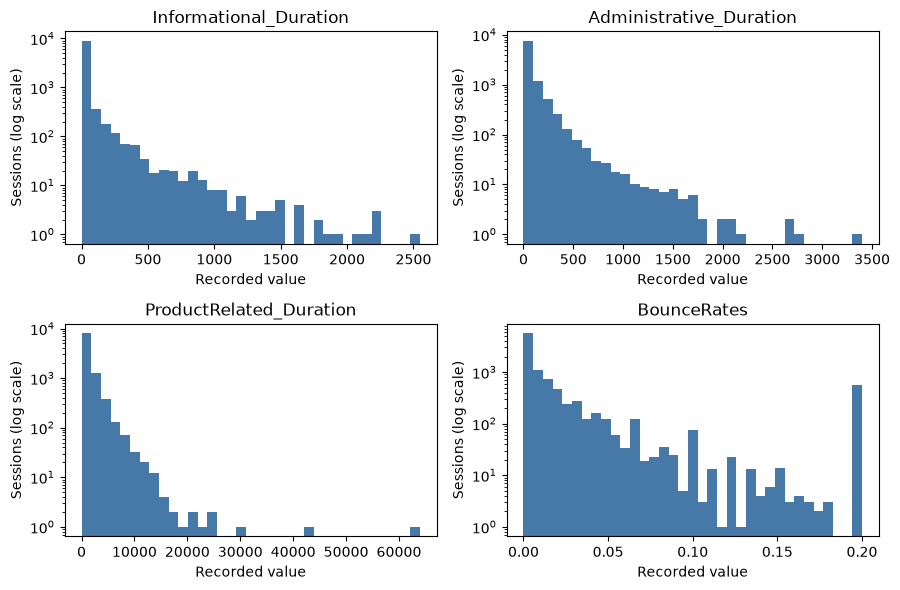

Activity fields with |skew|>2: ['Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration']
Activity fields with training zero share >=50%: ['Informational', 'Informational_Duration']
The training evidence shows long right tails across five of six activity fields and high zero prevalence for both informational measures; this supports evaluating the plan’s fixed log1p form and fold-fitted indicators for those high-zero fields. Strong within-class dependence (notably BounceRates/ExitRates and ProductRelated/ProductRelated_Duration) challenges Naive Bayes conditional independence. The observed class-specific correlation differences suggest possible covariance heterogeneity, but these selected pairs do not establish unequal full covariance matrices. Long tails and mixed numeric/nominal inputs challenge LDA’s multivariate Gaussian ideal; correlated predictors alone do not violate LDA’s covariance assumption. No model has been fitted or 

In [31]:
# Originally executed as training-only supplementary EDA. Saved outputs below are reproduced unchanged.
allnum=NUMERIC+['Weekend']; shape=pd.DataFrame({'skew':X[allnum].skew(),'zero_share':X[allnum].eq(0).mean(),'median':X[allnum].median(),'p95':X[allnum].quantile(.95)})
display(shape.round(4))
for cls in [0,1]:
    cor=X.loc[y==cls,allnum].corr().abs(); pairs=cor.where(np.triu(np.ones(cor.shape),1).astype(bool)).stack().sort_values(ascending=False).head(6); display(pairs.rename(f'class {cls} absolute correlation').to_frame())
def elogit(col):
    z=pd.DataFrame({'x':X[col],'buyer':y}); z['bin']='zero'
    positive=z.x.gt(0)
    if positive.any(): z.loc[positive,'bin']=pd.qcut(z.loc[positive,'x'],8,duplicates='drop').astype(str)
    out=z.groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyers=('buyer','sum'),rate=('buyer','mean')).reset_index()
    out['bin']=out['bin'].astype(str)
    out['empirical_logit']=np.log((out.buyers+.5)/(out.n-out.buyers+.5)); return out.sort_values('mean_x')
for col in ['Informational','Informational_Duration','Administrative','Administrative_Duration','ProductRelated_Duration','BounceRates']:
    print('Binned marginal empirical logit, zero retained as one stratum:',col); display(elogit(col).round(4))
fig,axs=plt.subplots(2,2,figsize=(9,6))
for ax,col in zip(axs.flat,['Informational_Duration','Administrative_Duration','ProductRelated_Duration','BounceRates']):
    ax.hist(X[col],bins=35,log=True,color='#4779a8'); ax.set(title=col,xlabel='Recorded value',ylabel='Sessions (log scale)')
plt.tight_layout(); plt.show()
activity=shape.loc[ACTIVITY]
print('Activity fields with |skew|>2:',activity.index[activity['skew'].abs()>2].tolist())
print('Activity fields with training zero share >=50%:',activity.index[activity['zero_share']>=.50].tolist())
print('The training evidence shows long right tails across five of six activity fields and high zero prevalence for both informational measures; this supports evaluating the plan’s fixed log1p form and fold-fitted indicators for those high-zero fields. Strong within-class dependence (notably BounceRates/ExitRates and ProductRelated/ProductRelated_Duration) challenges Naive Bayes conditional independence. The observed class-specific correlation differences suggest possible covariance heterogeneity, but these selected pairs do not establish unequal full covariance matrices. Long tails and mixed numeric/nominal inputs challenge LDA’s multivariate Gaussian ideal; correlated predictors alone do not violate LDA’s covariance assumption. No model has been fitted or compared.')

### EDA-to-experiment bridge

The following are **training-only descriptive observations**, not proof that a proposed transformation will improve future accuracy.

| Training EDA observation | Modelling hypotheses represented below |
|---|---|
| ProductRelated_Duration skew **8.01**, Informational_Duration skew **7.70**, Administrative_Duration skew **5.68** | L1, D1 and G1 test `log1p`; G7 and G8 test targeted marginal transformations; D9 tests winsorisation |
| Informational has **78.5% zeros**, Informational_Duration **80.5% zeros** | D10 tests positive-presence; L1 and other transforms account for zero-heavy engagement |
| BounceRates has **44.8% zeros** and skew **2.92** | L8 tests piecewise behaviour; D11 tests zero/low/high binning |
| Within-class BounceRates–ExitRates correlation **0.915** for nonbuyers and **0.723** for buyers | L4/L13/L14 test shrinkage; G2 and B4 test dropping a dependent input |
| Within-class ProductRelated–ProductRelated_Duration correlation **0.839** for nonbuyers and **0.896** for buyers | G3/G6 directly compare deleting different correlated inputs; D15 tests grouped feature elimination |
| Four Browser and nine TrafficType levels have fewer than 50 training observations | Fold-safe one-hot encoding and cautious interpretation; sparse categories are **not** an independent reason to claim improved AUC |

**Caution:** Marginal skewness does not establish multivariate Gaussianity; correlated predictors challenge Naive Bayes' conditional independence assumption. The original one-SE CV acceptance rule, not an EDA impression, determines which historical modification was retained.

**Complete supporting EDA** from the original supplementary notebook appears directly above: zero-versus-positive rates, activity intensity, VisitorType×Month support, rare nominal levels, SpecialDay patterns, decision-time feature availability, tails, within-class correlations and marginal empirical logits. Sections 7.1–7.4 refer to this evidence, not just numerical skewness alone.


In [6]:
# Reuse v2's source variables, data split, folds and basic model-evaluation contract.
# New v3 changes are deliberately isolated in this fold-fitted representation and evaluator.
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import calibration_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree

V3_ART=ARTIFACTS/'prd_v3_5' # Re-execution isolation only; presentation evidence remains frozen v3.4
V3_ART.mkdir(parents=True,exist_ok=True)
C_GRID=[0.05,0.2,1.0,5.0,20.0]
REG_C_GRID=[0.01,0.05,0.2,1.0,5.0,20.0]
SHRINKAGE_GRID=[0.0,0.1,0.3,0.6,0.9]
RARE_MIN_COUNT=50
INNER_FOLDS=3
FAMILY_ORDER=['Logit','LDA','GaussianNB','BernoulliNB']

class FoldSafeFeatures(BaseEstimator, TransformerMixin):
    """Train-fold-only feature engineering. Categorical levels are never treated as ordinal."""
    def __init__(self, family='Logit', columns=(), log_activity=False,
                 presence=False, rare_pool=False, special_binary=False,
                 drop_features=(), median_cols=(), scale=False,
                 presence_cols=(), log_cols=(), quadratic_cols=(),
                 special_categorical=False, drop_nominal=False,
                 bounce_piecewise=False, bounce_binned=False,
                 winsor_cols=(), avg_product_duration=False):
        self.family=family
        self.columns=columns
        self.log_activity=log_activity
        self.presence=presence
        self.rare_pool=rare_pool
        self.special_binary=special_binary
        self.drop_features=drop_features
        self.median_cols=median_cols
        self.scale=scale
        self.presence_cols=presence_cols
        self.log_cols=log_cols
        self.quadratic_cols=quadratic_cols
        self.special_categorical=special_categorical
        self.drop_nominal=drop_nominal
        self.bounce_piecewise=bounce_piecewise
        self.bounce_binned=bounce_binned
        self.winsor_cols=winsor_cols
        self.avg_product_duration=avg_product_duration

    def _blocks(self,X):
        active=[c for c in self.columns if c not in self.drop_features
                and not (self.drop_nominal and c in CAT)]
        cats=[c for c in CAT if c in active]
        if self.special_categorical and 'SpecialDay' in active:
            cats.append('SpecialDay')
        if self.bounce_binned and 'BounceRates' in active:
            cats.append('BounceRates')
        nums=[c for c in active if c not in cats]
        z=pd.DataFrame(index=X.index)
        for c in nums:
            value=X[c].astype(float)
            if c=='BounceRates' and self.bounce_piecewise:
                z['BounceRates__positive']=(value>0).astype(float)
                z['BounceRates__up_to_001']=np.minimum(value,0.01)
                z['BounceRates__above_001']=np.maximum(value-0.01,0.0)
                continue
            if c in self.winsor_cols:
                z[c]=value.clip(upper=self.winsor_cutoffs_[c])
                continue
            if self.family=='BernoulliNB':
                if c in self.median_cols:
                    z[c]=(value>self.medians_[c]).astype(float)
                elif c=='Weekend':
                    z[c]=value
                else:
                    z[c]=(value>0).astype(float)
            elif self.special_binary and c=='SpecialDay':
                z[c]=(value>0).astype(float)
            elif (self.log_activity and c in ACTIVITY) or c in self.log_cols:
                z[c]=np.log1p(value)
            else:
                z[c]=value
        if self.presence:
            for c in ('Informational','Informational_Duration'):
                if c in active:
                    z[c+'__positive']=(X[c].astype(float)>0).astype(float)
        for c in self.presence_cols:
            if c in active:
                z[c+'__positive']=(X[c].astype(float)>0).astype(float)
        for c in self.quadratic_cols:
            if c in active:
                z[c+'__squared']=X[c].astype(float)**2
        if self.avg_product_duration:
            # Zero page-count sessions receive 0, without dividing by zero.
            pages=X['ProductRelated'].astype(float).to_numpy()
            seconds=X['ProductRelated_Duration'].astype(float).to_numpy()
            z['ProductRelated__duration_per_page']=np.divide(
                seconds,pages,out=np.zeros_like(seconds,dtype=float),
                where=pages>0)
        cat=pd.DataFrame(index=X.index)
        for c in cats:
            if c=='BounceRates' and self.bounce_binned:
                b=X[c].astype(float)
                values=pd.Series(np.where(b.eq(0),'zero',
                    np.where(b.le(0.01),'low-positive','high-positive')),
                    index=X.index)
            else:
                values=X[c].astype(str)
            if self.rare_pool and c in ('Browser','TrafficType'):
                values=values.where(values.isin(self.major_levels_[c]),'__OTHER__')
            cat[c]=values
        return z,cat

    def fit(self,X,y=None):
        self.n_features_in_=X.shape[1]
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.major_levels_={}
        for c in ('Browser','TrafficType'):
            if c in X and self.rare_pool:
                counts=X[c].astype(str).value_counts()
                self.major_levels_[c]=set(counts.index[counts>=RARE_MIN_COUNT])
        self.medians_={c:float(X[c].median()) for c in self.median_cols}
        self.winsor_cutoffs_={c:float(X[c].quantile(0.99)) for c in self.winsor_cols}
        num,cat=self._blocks(X)
        self.numeric_names_=list(num.columns)
        self.categorical_names_=list(cat.columns)
        self.encoder_=OneHotEncoder(
            drop='first' if self.family in ('Logit','LDA') else None,
            handle_unknown='ignore',sparse_output=False
        )
        if self.categorical_names_:
            self.encoder_.fit(cat)
        transformed=self._encode(num,cat)
        if self.scale:
            self.scaler_=StandardScaler().fit(transformed)
        return self

    def _encode(self,num,cat):
        blocks=[num.to_numpy(dtype=float)]
        if self.categorical_names_:
            blocks.append(self.encoder_.transform(cat))
        Z=np.column_stack(blocks)
        if not np.isfinite(Z).all():
            raise ValueError('Non-finite preprocessing output')
        return Z

    def transform(self,X):
        num,cat=self._blocks(X)
        Z=self._encode(num,cat)
        return self.scaler_.transform(Z) if self.scale else Z

    def get_feature_names_out(self,input_features=None):
        names=list(self.numeric_names_)
        if self.categorical_names_:
            names+=list(self.encoder_.get_feature_names_out(self.categorical_names_))
        return np.asarray(names,dtype=object)


class BackwardSelectedLDA(BaseEstimator, ClassifierMixin):
    """Leakage-free grouped backward source selection inside each outer training fit.

    A fixed set of inner folds evaluates *every candidate removal* from the current
    subset, then chooses subset size by the course's simplest-within-1SE rule.
    Outer validation outcomes are never used in this search.
    """
    def __init__(self, columns=(), inner_folds=3, seed=42):
        self.columns=columns
        self.inner_folds=inner_folds
        self.seed=seed

    def fit(self,X,y):
        yv=np.asarray(y,dtype=int)
        cv=StratifiedKFold(n_splits=self.inner_folds,shuffle=True,random_state=self.seed)
        cached=[]
        for fit_idx,val_idx in cv.split(X,yv):
            pre=FoldSafeFeatures(family='LDA',columns=tuple(self.columns))
            zfit=pre.fit_transform(X.iloc[fit_idx])
            zval=pre.transform(X.iloc[val_idx])
            feat=list(pre.get_feature_names_out())
            groups={}
            for name in self.columns:
                if name in pre.numeric_names_:
                    groups[name]=[feat.index(name)]
                else:
                    groups[name]=[i for i,c in enumerate(feat) if c.startswith(name+'_')]
                if not groups[name]:
                    raise RuntimeError(f'No encoded columns for {name}')
            all_indices=[i for g in groups.values() for i in g]
            if len(all_indices)!=len(set(all_indices)) or sorted(all_indices)!=list(range(len(feat))):
                raise RuntimeError('Source-group index mapping is not a partition')
            cached.append((zfit,zval,yv[fit_idx],yv[val_idx],groups))

        def cross_validated_score(selected):
            fold_scores=[]
            for zfit,zval,yfit,yval,groups in cached:
                indices=sorted(i for name in selected for i in groups[name])
                clf=LinearDiscriminantAnalysis(solver='svd')
                clf.fit(zfit[:,indices],yfit)
                p=clf.predict_proba(zval[:,indices])[:,1]
                fold_scores.append(float(roc_auc_score(yval,p)))
            a=np.asarray(fold_scores,dtype=float)
            return float(a.mean()),float(a.std(ddof=1)/np.sqrt(len(a))),a.tolist()

        remaining=tuple(self.columns)
        self.selection_path_=[]
        prior=None
        while True:
            if prior is None:
                candidates=[remaining]
            else:
                candidates=[tuple(c for c in remaining if c!=drop) for drop in remaining]
            options=[]
            for option in candidates:
                avg,se,fold_scores=cross_validated_score(option)
                # Maximise AUC; stable tie by original order of the removed source.
                options.append((avg,se,fold_scores,option))
            options.sort(key=lambda x:(-x[0],tuple(self.columns.index(c) for c in x[3])))
            avg,se,fold_scores,chosen=options[0]
            self.selection_path_.append({'source_count':len(chosen),'selected_sources':list(chosen),
                        'inner_mean_auc':avg,'inner_auc_se':se,
                        'inner_fold_aucs':fold_scores})
            remaining=chosen
            prior=True
            if len(remaining)==1:
                break
        best=sorted(self.selection_path_,key=lambda v:(-v['inner_mean_auc'],-v['source_count']))[0]
        self.one_se_cutoff_=best['inner_mean_auc']-best['inner_auc_se']
        eligible=[p for p in self.selection_path_
                  if p['inner_mean_auc']>=self.one_se_cutoff_-1e-14]
        selected=sorted(eligible,key=lambda p:(p['source_count'],-p['inner_mean_auc']))[0]
        self.selected_source_cols_=tuple(selected['selected_sources'])
        self.selected_source_count_=len(self.selected_source_cols_)
        self.inner_selected_auc_=selected['inner_mean_auc']
        self.inner_best_size_=best['source_count']
        self.model_=Pipeline([
            ('pre',FoldSafeFeatures(family='LDA',columns=self.selected_source_cols_)),
            ('clf',LinearDiscriminantAnalysis(solver='svd'))
        ])
        self.model_.fit(X,y)
        self.named_steps=self.model_.named_steps
        self.classes_=self.model_.named_steps['clf'].classes_
        self.n_features_in_=X.shape[1]
        return self

    def predict_proba(self,X):
        return self.model_.predict_proba(X)

    def predict(self,X):
        return self.model_.predict(X)

def build_model(family,config=None,columns=SAFE):
    cfg=dict(config or {})
    tune=cfg.pop('tune',None)
    backward=bool(cfg.pop('backward_select',False))
    if backward:
        if family!='LDA' or tune is not None or cfg:
            raise ValueError('Backward source selection only supports D0 LDA')
        return BackwardSelectedLDA(columns=tuple(columns),inner_folds=INNER_FOLDS,seed=SEED)
    pre=FoldSafeFeatures(family=family,columns=tuple(columns),**cfg)
    if family=='Logit':
        if tune=='logit':
            clf=LogisticRegression(solver='lbfgs',max_iter=1600,tol=1e-6)
        elif tune=='lasso':
            clf=LogisticRegression(penalty='l1',solver='saga',
                                    max_iter=10000,tol=1e-4,random_state=SEED)
        elif tune=='elasticnet':
            clf=LogisticRegression(penalty='elasticnet',l1_ratio=0.5,solver='saga',
                                    max_iter=10000,tol=1e-4,random_state=SEED)
        elif tune is None:
            clf=LogisticRegression(C=np.inf,solver='newton-cg',tol=1e-8,max_iter=2000)
        else:
            raise ValueError(f'Unknown Logit penalty: {tune}')
    elif family=='LDA':
        clf=LinearDiscriminantAnalysis(solver='lsqr' if tune=='lda' else 'svd')
    elif family=='GaussianNB':
        clf=GaussianNB()
    elif family=='BernoulliNB':
        clf=BernoulliNB(binarize=None)
    else:
        raise ValueError(family)
    pipe=Pipeline([('pre',pre),('clf',clf)])
    if tune:
        if tune in ('logit','lasso','elasticnet'):
            params={'clf__C':REG_C_GRID if tune in ('lasso','elasticnet') else C_GRID}
        elif tune=='lda':
            params={'clf__shrinkage':SHRINKAGE_GRID}
        else:
            raise ValueError(f'Unsupported tune: {tune}')
        inner=StratifiedKFold(n_splits=INNER_FOLDS,shuffle=True,random_state=SEED)
        return GridSearchCV(pipe,params,cv=inner,scoring='roc_auc',
                            n_jobs=1,refit=True,error_score='raise')
    return pipe

def make_pipeline(columns,family,estimator=None):
    if estimator is not None:
        raise ValueError('v3 uses explicit configurations, not replacement estimators')
    return build_model(family,{},columns)

def compact_numerical_label(result):
    return result.get('numerical_status','UNKNOWN')

BACKWARD_PATH_ROWS=[]
def tune_is_regularized(model):
    if isinstance(model,GridSearchCV):
        estimator=model.best_estimator_.named_steps['clf']
        return getattr(estimator,'penalty',None) in ('l1','elasticnet')
    return False

def run_spec(label,family,columns,pipeline_factory=None):
    oof=np.full(len(ytr),np.nan)
    folds=[]; warning_rows=[]
    for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
        fit_x=Xtr.iloc[fit_idx][columns]
        val_x=Xtr.iloc[val_idx][columns]
        fit_y=ytr.iloc[fit_idx]
        val_y=ytr.iloc[val_idx]
        fitted=pipeline_factory() if pipeline_factory is not None else make_pipeline(columns,family)
        mark_progress(label,fold,'start',n_fit=len(fit_idx),n_validation=len(val_idx))
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            fitted.fit(fit_x,fit_y)
            prob=np.asarray(fitted.predict_proba(val_x)[:,1],dtype=float)
        actual=fitted.best_estimator_ if isinstance(fitted,GridSearchCV) else fitted
        if isinstance(actual,BackwardSelectedLDA):
            for rec in actual.selection_path_:
                BACKWARD_PATH_ROWS.append({'candidate':label,'outer_fold':fold,
                    'source_count':rec['source_count'],
                    'selected_sources':json.dumps(rec['selected_sources']),
                    'inner_mean_auc':rec['inner_mean_auc'],
                    'inner_auc_se':rec['inner_auc_se'],
                    'one_se_cutoff':actual.one_se_cutoff_,
                    'chosen_size':actual.selected_source_count_,
                    'is_selected':rec['source_count']==actual.selected_source_count_})
        clf=actual.named_steps['clf']
        params=['coef_','intercept_','theta_','var_','class_prior_','feature_log_prob_',
                'means_','priors_','scalings_','class_log_prior_']
        finite=all(np.isfinite(np.asarray(getattr(clf,k),dtype=float)).all()
                   for k in params if hasattr(clf,k))
        if not finite or not np.isfinite(prob).all() or np.any((prob<0)|(prob>1)):
            raise RuntimeError(f'{label} fold {fold}: invalid model parameters/probabilities')
        oof[val_idx]=prob
        for w in caught:
            warning_rows.append({'candidate':label,'fold':fold,
                                 'warning_type':w.category.__name__,
                                 'message':str(w.message)[:350]})
        best=fitted.best_params_ if isinstance(fitted,GridSearchCV) else {}
        row={'candidate':label,'family':family,'fold':fold,'fit_status':'OK',
             'n_fit':len(fit_idx),'n_validation':len(val_idx),
             'roc_auc':float(roc_auc_score(val_y,prob)),
             'average_precision':float(average_precision_score(val_y,prob)),
             'design_rank':np.nan,'design_columns':actual.named_steps['pre'].transform(fit_x.iloc[:1]).shape[1],
             'finite_model_parameters':bool(finite),'finite_probabilities':True,
             'probabilities_in_0_1':True,'inner_cv_best_params':json.dumps(best),
             'nonzero_coefficients':(int(np.sum(np.abs(clf.coef_)>1e-10))
                  if hasattr(clf,'coef_') and tune_is_regularized(fitted) else np.nan),
             'selected_source_count':(actual.selected_source_count_
                  if isinstance(actual,BackwardSelectedLDA) else np.nan),
             'selected_source_cols':(json.dumps(actual.selected_source_cols_)
                  if isinstance(actual,BackwardSelectedLDA) else ''),
             'numerical_status':'FINITE_WITH_WARNINGS_REVIEW_REQUIRED' if caught else 'FINITE_FIT'}
        folds.append(row)
        mark_progress(label,fold,'complete',roc_auc=row['roc_auc'])
    if np.isnan(oof).any():
        raise RuntimeError(f'{label}: incomplete OOF coverage')
    auc=np.array([x['roc_auc'] for x in folds],dtype=float)
    ap=np.array([x['average_precision'] for x in folds],dtype=float)
    return {'candidate':label,'family':family,'stage':'all17' if len(columns)==len(ALL) else 'operational16',
            'status':'SCORED','numerical_status':'FINITE_WITH_WARNINGS_REVIEW_REQUIRED' if warning_rows else 'FINITE_FIT',
            'folds':folds,'oof':oof,'warnings':warning_rows,'failure':'',
            'mean_fold_auc':float(auc.mean()),
            'fold_auc_sd':float(auc.std(ddof=1)),
            'fold_auc_se':float(auc.std(ddof=1)/np.sqrt(K)),
            'mean_fold_ap':float(ap.mean()),
            'fold_ap_sd':float(ap.std(ddof=1)),
            'fold_ap_se':float(ap.std(ddof=1)/np.sqrt(K)),
            'pooled_oof_auc':float(roc_auc_score(ytr,oof)),
            'pooled_oof_ap':float(average_precision_score(ytr,oof))}

# The two trees share the existing fold-safe full-indicator nominal encoding.
# Growth settings and seed are fixed by PRD v3.3; only ccp_alpha is tuned.
TREE_FAMILIES={'GiniTree':'gini','EntropyTree':'entropy'}
def tree_pipeline(family,alpha=0.,columns=SAFE):
    assert family in TREE_FAMILIES
    return Pipeline([('pre',FoldSafeFeatures(family=family,columns=tuple(columns))),
       ('clf',DecisionTreeClassifier(criterion=TREE_FAMILIES[family],
           ccp_alpha=float(alpha),max_depth=None,min_samples_leaf=1,
           min_samples_split=2,class_weight=None,random_state=SEED))])

RESULTS={}; FOLD_ROWS=[]; WARNING_ROWS=[]

## 5. Six all-17 first-pass models

**Purpose.** Start with every source predictor.

**Method.** Compare the four established classifiers and full-grown Gini/Entropy trees on the same training folds; none is eligible for operational selection.

**Implication.** This is a diagnostic pass, not the operational model selection.


In [7]:
# A5 — diagnostic first pass, all 17 predictors
for family in ['Logit','GaussianNB','BernoulliNB','LDA',*TREE_FAMILIES]:
    label=f'All17 | {family}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,ALL,
        pipeline_factory=(lambda f=family:tree_pipeline(f,0.,ALL)) if family in TREE_FAMILIES else None)
    FOLD_ROWS.extend(RESULTS[label]['folds']); WARNING_ROWS.extend(RESULTS[label]['warnings'])
ALL17=pd.DataFrame([{'candidate':r['candidate'],'scoring status':r['status'],'numerical status':compact_numerical_label(r),'mean ROC-AUC':r.get('mean_fold_auc',np.nan),
 'AUC SD':r.get('fold_auc_sd',np.nan),'AUC SE':r.get('fold_auc_se',np.nan),'mean AP':r.get('mean_fold_ap',np.nan),
 'pooled OOF AUC':r.get('pooled_oof_auc',np.nan),'warnings':len(r['warnings']),'failure':r['failure']} for r in RESULTS.values() if r['stage']=='all17']).set_index('candidate')
display(ALL17[['mean ROC-AUC','AUC SD','mean AP']].round(4))
fold_diag=pd.DataFrame([x for r in RESULTS.values() if r['stage']=='all17' for x in r['folds']])
all17_audit=fold_diag.groupby('candidate').agg(rank_min=('design_rank','min'),rank_max=('design_rank','max'),
    encoded_columns_min=('design_columns','min'),encoded_columns_max=('design_columns','max'),
    all_parameters_finite=('finite_model_parameters','all'),all_probabilities_in_range=('probabilities_in_0_1','all'))
logit_diag=fold_diag[fold_diag.family.eq('Logit')].copy()

assert len(ALL17)==6
ALL17.to_csv(V3_ART/'six_all17_diagnostics.csv')


Fitting All17 | Logit


Fitting All17 | GaussianNB


Fitting All17 | BernoulliNB


Fitting All17 | LDA


Fitting All17 | GiniTree


Fitting All17 | EntropyTree


,mean ROC-AUC,AUC SD,mean AP
candidate,,,
All17 | Logit,0.8897,0.0063,0.6443
All17 | GaussianNB,0.7879,0.0145,0.4334
All17 | BernoulliNB,0.8766,0.0105,0.5345
All17 | LDA,0.8997,0.0033,0.6469
All17 | GiniTree,0.7421,0.0101,0.3850
All17 | EntropyTree,0.7455,0.0102,0.3867


**Interpretation.** `PageValues` may be unavailable when prediction would be required. Exclude it from operational models as a precaution; a strong association alone does not establish leakage.


In [8]:
# PageValues descriptive association on training rows only
pv=Xtr.assign(Revenue=ytr).groupby(Xtr.PageValues.gt(0).map({False:'PageValues = 0',True:'PageValues > 0'})).Revenue.agg(sessions='size',buyers='sum',buyer_rate='mean')
display(pv)
print('The above difference is descriptive. PageValues is excluded from operational predictors because its availability at the intended prediction time is uncertain, not because association proves leakage.')


,sessions,buyers,buyer_rate
PageValues,,,
PageValues = 0,7671,286,0.037283
PageValues > 0,2193,1240,0.565435


The above difference is descriptive. PageValues is excluded from operational predictors because its availability at the intended prediction time is uncertain, not because association proves leakage.


## 6. Six operational baselines

**Purpose.** Evaluate the taught families using the 16 decision-time candidates.

**Method.** Compare four existing baselines and the two full-grown trees using identical folds and fold-fitted nominal encoding; quantify the AUC change from excluding `PageValues`.

**Implication.** Baselines provide the reference for targeted modifications.


In [9]:
# A6 — four operational 16-source-predictor baselines
for family in ['Logit','GaussianNB','BernoulliNB','LDA',*TREE_FAMILIES]:
    label=f'Operational16 | {family}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,family,SAFE,
        pipeline_factory=(lambda f=family:tree_pipeline(f,0.,SAFE)) if family in TREE_FAMILIES else None)
    FOLD_ROWS.extend(RESULTS[label]['folds']); WARNING_ROWS.extend(RESULTS[label]['warnings'])
OP16=pd.DataFrame([{'candidate':r['candidate'],'scoring status':r['status'],'numerical status':compact_numerical_label(r),'mean ROC-AUC':r.get('mean_fold_auc',np.nan),
 'AUC SD':r.get('fold_auc_sd',np.nan),'AUC SE':r.get('fold_auc_se',np.nan),'mean AP':r.get('mean_fold_ap',np.nan),
 'pooled OOF AUC':r.get('pooled_oof_auc',np.nan),'warnings':len(r['warnings']),'failure':r['failure']} for r in RESULTS.values() if r['stage']=='operational16']).set_index('candidate')
display(OP16[['mean ROC-AUC','AUC SD','mean AP']].round(4))
op16_fold_diag=pd.DataFrame([x for r in RESULTS.values() if r['stage']=='operational16' for x in r['folds']])
op16_audit=op16_fold_diag.groupby('candidate').agg(rank_min=('design_rank','min'),rank_max=('design_rank','max'),
    encoded_columns_min=('design_columns','min'),encoded_columns_max=('design_columns','max'),
    all_parameters_finite=('finite_model_parameters','all'),all_probabilities_in_range=('probabilities_in_0_1','all'))
# Direct same-fold AUC changes quantify the effect of omitting PageValues in each family.
comparison=[]
for family in ['Logit','GaussianNB','BernoulliNB','LDA',*TREE_FAMILIES]:
    a=RESULTS[f'All17 | {family}']; b=RESULTS[f'Operational16 | {family}']
    if a['status']=='SCORED' and b['status']=='SCORED':
        for x,y in zip(a['folds'],b['folds']): comparison.append({'family':family,'fold':x['fold'],'AUC all17':x['roc_auc'],'AUC op16':y['roc_auc'],'op16 minus all17':y['roc_auc']-x['roc_auc']})
PAGE_COMPARE=pd.DataFrame(comparison)
PAGE_SUMMARY=PAGE_COMPARE.groupby('family')['op16 minus all17'].agg(['mean','std']).rename(columns={'mean':'mean AUC delta','std':'fold SD'}).round(4)
display(PAGE_SUMMARY[['mean AUC delta']])

print(f'Interpretation: operational Logit starts at CV mean AUC {OP16.loc["Operational16 | Logit","mean ROC-AUC"]:.4f}, versus {ALL17.loc["All17 | Logit","mean ROC-AUC"]:.4f} with PageValues. Exclusion is a timing precaution, not proof of leakage.')

assert len(OP16)==6 and PAGE_COMPARE.family.nunique()==6
ALL17_VS_16=pd.DataFrame([{'family':f,
    'all17_mean_auc':RESULTS[f'All17 | {f}']['mean_fold_auc'],
    'operational16_mean_auc':RESULTS[f'Operational16 | {f}']['mean_fold_auc'],
    'all17_mean_ap':RESULTS[f'All17 | {f}']['mean_fold_ap'],
    'operational16_mean_ap':RESULTS[f'Operational16 | {f}']['mean_fold_ap']}
    for f in [*FAMILY_ORDER,*TREE_FAMILIES]])
OP16.to_csv(V3_ART/'six_operational_baselines.csv')
ALL17_VS_16.to_csv(V3_ART/'all17_vs_operational16.csv',index=False)
PAGE_COMPARE.to_csv(V3_ART/'all17_vs_operational16_folds.csv',index=False)
display(ALL17_VS_16.round(5))
print('Gini and Entropy all-17 diagnostic scores do not enter pruning or winner selection.')


Fitting Operational16 | Logit


Fitting Operational16 | GaussianNB


Fitting Operational16 | BernoulliNB


Fitting Operational16 | LDA


Fitting Operational16 | GiniTree


Fitting Operational16 | EntropyTree


,mean ROC-AUC,AUC SD,mean AP
candidate,,,
Operational16 | Logit,0.7500,0.0122,0.3250
Operational16 | GaussianNB,0.6920,0.0206,0.2574
Operational16 | BernoulliNB,0.7231,0.0182,0.2764
Operational16 | LDA,0.7409,0.0128,0.3165
Operational16 | GiniTree,0.5766,0.0157,0.1902
Operational16 | EntropyTree,0.5797,0.0052,0.1929


,mean AUC delta
family,
BernoulliNB,-0.1534
EntropyTree,-0.1657
GaussianNB,-0.0959
GiniTree,-0.1655
LDA,-0.1588
Logit,-0.1397


Interpretation: operational Logit starts at CV mean AUC 0.7500, versus 0.8897 with PageValues. Exclusion is a timing precaution, not proof of leakage.


,family,all17_mean_auc,operational16_mean_auc,all17_mean_ap,operational16_mean_ap
0,Logit,0.88972,0.75002,0.64433,0.32496
1,LDA,0.89965,0.74088,0.64695,0.31649
2,GaussianNB,0.78795,0.69202,0.43345,0.25745
3,BernoulliNB,0.87656,0.72313,0.53448,0.27635
4,GiniTree,0.74214,0.57663,0.38504,0.19015
5,EntropyTree,0.74547,0.57973,0.38673,0.19288


Gini and Entropy all-17 diagnostic scores do not enter pruning or winner selection.


## 7. EDA-grounded model development — 26 shortlisted trials

We report the **numeric evaluation** (five-fold AUC, fold SE, average precision and AUC gain relative to the original comparison parent) in a compact table for each family. **Below each table**, an iteration-by-iteration explanation describes the change, supporting EDA or taught method, actual parent, and accepted/reverted decision.

The historical **gain > challenger AUC SE** criterion is unchanged; this was a project selection heuristic, **not** a formal significance test. All model code and numerical outcomes remain frozen. Method coverage from Lectures 8 and 9 is explained where those techniques were attempted (D15; L4, L13 and L14); there is no separate methods matrix.

In [10]:
# Inherit every historical model definition and rule from the executed v3.3 notebook.
# Only the orchestration order changes: each family is now shown start-to-finish.
# Predeclare the ordered list of single changes. Edits are cumulative only if accepted.
PATHS={
 'Logit':[('L1','log1p six activity magnitudes',{'log_activity':True}),
          ('L2','separate informational positive-presence indicators',{'presence':True}),
          ('L3','fold-fitted pooling of rare Browser/TrafficType levels',{'rare_pool':True}),
          ('L4','standardised L2 logistic with inner-CV C',{'scale':True,'tune':'logit'})],
 'LDA':[('D1','log1p six activity magnitudes',{'log_activity':True}),
        ('D2','binarise SpecialDay>0',{'special_binary':True}),
        ('D3','fold-fitted rare nominal-level pooling',{'rare_pool':True}),
        ('D4','inner-CV covariance shrinkage',{'tune':'lda'})],
 'GaussianNB':[('G1','log1p six activity magnitudes',{'log_activity':True}),
               ('G2','remove BounceRates, retaining ExitRates',{'remove':'BounceRates'}),
               ('G3','remove ProductRelated, retaining duration',{'remove':'ProductRelated'}),
               ('G4','remove SpecialDay Gaussian marginal',{'remove':'SpecialDay'})],
 'BernoulliNB':[('B1','ProductRelated: presence to training-fold median',{'median':'ProductRelated'}),
                ('B2','ProductRelated_Duration: training-fold median',{'median':'ProductRelated_Duration'}),
                ('B3','ExitRates: training-fold median',{'median':'ExitRates'}),
                ('B4','remove BounceRates',{'remove':'BounceRates'})]}

EXTRA_PATHS={
 'Logit':[
  ('L5','add BounceRates squared term, retaining linear term',{'quadratic_cols':('BounceRates',)}),
  ('L6','add Administrative positive-presence indicator',{'presence_cols':('Administrative',)}),
  ('L7','add ProductRelated_Duration positive-presence indicator',{'presence_cols':('ProductRelated_Duration',)})],
 'LDA':[
  ('D5','log1p ProductRelated_Duration only',{'log_cols':('ProductRelated_Duration',)}),
  ('D6','log1p Administrative_Duration only',{'log_cols':('Administrative_Duration',)}),
  ('D7','encode SpecialDay as categorical instead of numeric',{'special_categorical':True})],
 'GaussianNB':[
  ('G5','remove ExitRates, retain BounceRates',{'drop_features':('ExitRates',)}),
  ('G6','remove ProductRelated_Duration, retain ProductRelated',{'drop_features':('ProductRelated_Duration',)}),
  ('G7','log1p ProductRelated_Duration only',{'log_cols':('ProductRelated_Duration',)}),
  ('G8','log1p Administrative_Duration only',{'log_cols':('Administrative_Duration',)}),
  ('G9','exclude all six nominal sources',{'drop_nominal':True})],
 'BernoulliNB':[]
}

V33_EXTRAS={
 'Logit':[
  ('L8','replace BounceRates with fixed 0.01-knot piecewise linear basis',
   {'bounce_piecewise':True}),
  ('L9','encode SpecialDay as fold-fitted nominal categories',
   {'special_categorical':True}),
  ('L10','add safe ProductRelated_Duration per ProductRelated page ratio',
   {'avg_product_duration':True})],
 'LDA':[
  ('D8','log1p ProductRelated count only',{'log_cols':('ProductRelated',)}),
  ('D9','winsorise ProductRelated_Duration at fold-training p99',
   {'winsor_cols':('ProductRelated_Duration',)}),
  ('D10','add Informational positive-presence indicator',
   {'presence_cols':('Informational',)}),
  ('D11','replace BounceRates with zero/low/high categorical bands',
   {'bounce_binned':True})],
 'GaussianNB':[],
 'BernoulliNB':[]
}

PATH_FINALISTS={}; PATH_FINAL_CONFIGS={}; ATTEMPTS=[]
V31_PATH_FINALISTS={}; V31_PATH_FINAL_CONFIGS={}
V32_PATH_FINALISTS={}; V32_PATH_FINAL_CONFIGS={}; V32_PROBE_SELECTION={}
V33_PATH_FINALISTS={}; V33_PATH_FINAL_CONFIGS={}; V33_PROBE_SELECTION={}
V34_PROBE_SELECTION={}

def run_v31_family(fam):
    prefix={'Logit':'L','LDA':'D','GaussianNB':'G','BernoulliNB':'B'}[fam]
    baseline=f'Operational16 | {fam}'
    incumbent_label=baseline
    incumbent_cfg={}
    b=RESULTS[baseline]
    ATTEMPTS.append({'pathway':fam,'step':prefix+'0','candidate':baseline,
          'parent':'—','single_change':'16-source operational baseline',
          'eda_reason':'Four all-16 operational reference models',
          'mean_auc':b['mean_fold_auc'],'auc_sd':b['fold_auc_sd'],
          'auc_se':b['fold_auc_se'],'mean_ap':b['mean_fold_ap'],
          'delta_auc':np.nan,'accepted':True,'decision':'Baseline'})
    for step,reason,change in PATHS[fam]:
        cfg=incumbent_cfg.copy()
        if 'remove' in change:
            cfg['drop_features']=tuple([*cfg.get('drop_features',()),change['remove']])
        elif 'median' in change:
            cfg['median_cols']=tuple([*cfg.get('median_cols',()),change['median']])
        else:
            cfg.update(change)
        label=step+' | '+fam
        print(f'Testing {label} (against {incumbent_label})',flush=True)
        res=run_spec(label,fam,SAFE,
            pipeline_factory=lambda f=fam,c=cfg:build_model(f,c,SAFE))
        RESULTS[label]=res
        FOLD_ROWS.extend(res['folds'])
        WARNING_ROWS.extend(res['warnings'])
        prior=RESULTS[incumbent_label]
        gain=res['mean_fold_auc']-prior['mean_fold_auc']
        accept=bool(gain>res['fold_auc_se'])
        ATTEMPTS.append({'pathway':fam,'step':step,'candidate':label,
            'parent':incumbent_label,'single_change':reason,
            'eda_reason':reason,
            'mean_auc':res['mean_fold_auc'],'auc_sd':res['fold_auc_sd'],
            'auc_se':res['fold_auc_se'],'mean_ap':res['mean_fold_ap'],
            'delta_auc':gain,'accepted':accept,
            'decision':'Retain' if accept else 'Revert (within 1 SE or no gain)'})
        if accept:
            incumbent_label=label
            incumbent_cfg=cfg
    PATH_FINALISTS[fam]=incumbent_label
    PATH_FINAL_CONFIGS[fam]=incumbent_cfg.copy()
    V31_PATH_FINALISTS[fam]=PATH_FINALISTS[fam]
    V31_PATH_FINAL_CONFIGS[fam]=PATH_FINAL_CONFIGS[fam].copy()

def run_v32_family(family):
    anchor=V31_PATH_FINALISTS[family]
    anchor_cfg=V31_PATH_FINAL_CONFIGS[family].copy()
    qualified=[]
    for step,reason,change in EXTRA_PATHS[family]:
        cfg=anchor_cfg.copy()
        cfg.update(change)
        label=step+' | '+family
        print(f'V3.2 anchored trial {label} against {anchor}',flush=True)
        res=run_spec(label,family,SAFE,
            pipeline_factory=lambda f=family,c=cfg:build_model(f,c,SAFE))
        RESULTS[label]=res
        FOLD_ROWS.extend(res['folds'])
        WARNING_ROWS.extend(res['warnings'])
        gain=res['mean_fold_auc']-RESULTS[anchor]['mean_fold_auc']
        qualifies=bool(gain>res['fold_auc_se'])
        ATTEMPTS.append({'pathway':family,'step':step,'candidate':label,
          'parent':anchor,'single_change':reason,'eda_reason':reason,
          'mean_auc':res['mean_fold_auc'],'auc_sd':res['fold_auc_sd'],
          'auc_se':res['fold_auc_se'],'mean_ap':res['mean_fold_ap'],
          'delta_auc':gain,'accepted':qualifies,
          'decision':'Qualifies vs v3.1 anchor' if qualifies else 'Does not qualify vs v3.1 anchor',
          'trial_version':'v3.2','new_change':repr(change)})
        if qualifies:
            qualified.append((res['mean_fold_auc'],step,label,cfg))
    if qualified:
        qualified.sort(key=lambda p:(-p[0],p[1]))
        best=qualified[0]
        PATH_FINALISTS[family]=best[2]
        PATH_FINAL_CONFIGS[family]=best[3].copy()
    V32_PROBE_SELECTION[family]={'anchor':anchor,'selected':PATH_FINALISTS[family],
                                'qualified':[q[2] for q in qualified]}
    V32_PATH_FINALISTS[family]=PATH_FINALISTS[family]
    V32_PATH_FINAL_CONFIGS[family]=PATH_FINAL_CONFIGS[family].copy()

def run_v33_family(family):
    anchor=V32_PATH_FINALISTS[family]
    anchor_cfg=V32_PATH_FINAL_CONFIGS[family].copy()
    qualified=[]
    for step,reason,change_spec in V33_EXTRAS[family]:
        candidate_cfg=anchor_cfg.copy()
        candidate_cfg.update(change_spec)
        label=step+' | '+family
        print(f'V3.3 anchored trial {label} vs {anchor}',flush=True)
        res=run_spec(label,family,SAFE,
            pipeline_factory=lambda f=family,c=candidate_cfg:build_model(f,c,SAFE))
        RESULTS[label]=res
        FOLD_ROWS.extend(res['folds'])
        WARNING_ROWS.extend(res['warnings'])
        delta=res['mean_fold_auc']-RESULTS[anchor]['mean_fold_auc']
        qualifies=bool(delta>res['fold_auc_se'])
        ATTEMPTS.append({'pathway':family,'step':step,'candidate':label,
          'parent':anchor,'single_change':reason,'eda_reason':reason,
          'mean_auc':res['mean_fold_auc'],'auc_sd':res['fold_auc_sd'],
          'auc_se':res['fold_auc_se'],'mean_ap':res['mean_fold_ap'],
          'delta_auc':delta,'accepted':qualifies,
          'decision':'Qualifies vs v3.2 anchor' if qualifies
                     else 'Does not qualify vs v3.2 anchor',
          'trial_version':'v3.3','new_change':repr(change_spec)})
        if qualifies:
            qualified.append((res['mean_fold_auc'],step,label,candidate_cfg))
    if qualified:
        qualified.sort(key=lambda z:(-z[0],z[1]))
        chosen=qualified[0]
        PATH_FINALISTS[family]=chosen[2]
        PATH_FINAL_CONFIGS[family]=chosen[3].copy()
    V33_PROBE_SELECTION[family]={'anchor':anchor,
         'selected':PATH_FINALISTS[family],
         'qualified':[x[2] for x in qualified]}
    V33_PATH_FINALISTS[family]=PATH_FINALISTS[family]
    V33_PATH_FINAL_CONFIGS[family]=PATH_FINAL_CONFIGS[family].copy()


V34_EXTRAS={
 'Logit':[
  ('L13','LASSO logistic: fold-scaled L1 penalty and inner-CV C',{'scale':True,'tune':'lasso'}),
  ('L14','Elastic Net logistic: fold-scaled fixed 0.5 L1 ratio and inner-CV C',
       {'scale':True,'tune':'elasticnet'})],
 'LDA':[('D15','Grouped backward LDA selection nested within outer CV',
         {'backward_select':True})],
 'GaussianNB':[],
 'BernoulliNB':[]
}
def run_v34_family(family):
    qualified=[]
    prior=PATH_FINALISTS[family]
    prior_cfg=PATH_FINAL_CONFIGS[family].copy()
    for step,reason,change in V34_EXTRAS[family]:
        cfg=prior_cfg.copy()
        if family=='Logit':
            # The penalty REPLACES the preceding logistic penalty, never stacks it.
            cfg.pop('tune',None)
        cfg.update(change)
        label=step+' | '+family
        print(f'V3.4 sequential trial {label} vs latest accepted {prior}',flush=True)
        res=run_spec(label,family,SAFE,
           pipeline_factory=lambda f=family,c=cfg:build_model(f,c,SAFE))
        RESULTS[label]=res
        FOLD_ROWS.extend(res['folds'])
        WARNING_ROWS.extend(res['warnings'])
        gain=res['mean_fold_auc']-RESULTS[prior]['mean_fold_auc']
        accept=bool(gain>res['fold_auc_se'])
        ATTEMPTS.append({'pathway':family,'step':step,'candidate':label,
          'parent':prior,'single_change':reason,'eda_reason':reason,
          'mean_auc':res['mean_fold_auc'],'auc_sd':res['fold_auc_sd'],
          'auc_se':res['fold_auc_se'],'mean_ap':res['mean_fold_ap'],
          'delta_auc':gain,'accepted':accept,
          'decision':'Retain vs latest accepted' if accept
               else 'Revert to latest accepted (within 1 SE or lower AUC)',
          'trial_version':'v3.4','new_change':repr(change)})
        if accept:
            prior=label
            prior_cfg=cfg.copy()
            qualified.append(label)
    PATH_FINALISTS[family]=prior
    PATH_FINAL_CONFIGS[family]=prior_cfg.copy()
    V34_PROBE_SELECTION[family]={'anchor':V33_PATH_FINALISTS[family],
          'selected':prior,'accepted_in_order':qualified}


# PRD v3.5 is a display-only view of the original 41-trial history.
# The rationale text and seven-per-family selections come directly from PRD v3.5.
# None of these labels, statuses or display filters is used to fit or select a model.
V35_CURATION=json.loads(r'''{"Logit":[{"id":"L0","change":"Operational 16-predictor baseline","rationale":"Baseline; no EDA hypothesis","verdict":"Baseline"},{"id":"L1","change":"log1p on six activity predictors","rationale":"All six activity variables are right-skewed, notably ProductRelated_Duration (skew 8.01) and Informational_Duration (7.70); log1p preserves zero readings","verdict":"Accepted · retained"},{"id":"L4","change":"Standardised L2-penalised Logit, inner-CV C","rationale":"Strong within-class correlations, including BounceRates–ExitRates (0.915 nonbuyers; 0.723 buyers), motivate regularisation (Lecture 9)","verdict":"Not accepted"},{"id":"L7","change":"ProductRelated_Duration positive-presence indicator","rationale":"ProductRelated_Duration is extremely skewed (8.01), with 6.2% zeros; test whether zero versus any activity adds information beyond amount","verdict":"Not accepted"},{"id":"L8","change":"Fixed-knot piecewise-linear BounceRates","rationale":"BounceRates is zero in 44.8% of sessions and skewed (2.92); examine a possible nonlinear predictive effect without claiming EDA chose the knot","verdict":"Not accepted"},{"id":"L13","change":"LASSO (L1) Logistic, inner-CV C","rationale":"Redundant and correlated features motivate sparse shrinkage, a classification adaptation of Lecture 9","verdict":"Not accepted"},{"id":"L14","change":"Elastic Net Logistic (fixed L1 ratio 0.5), inner-CV C","rationale":"Correlated predictor blocks motivate combined L1/L2 shrinkage (Lecture 9), replacing rather than stacking the LASSO penalty","verdict":"Not accepted"}],"LDA":[{"id":"D0","change":"Operational 16-predictor LDA baseline","rationale":"Baseline","verdict":"Baseline · retained"},{"id":"D1","change":"log1p on six activity predictors","rationale":"Strong right-skew and non-normal duration Q–Q plots motivate checking more Gaussian-like marginal inputs","verdict":"Not accepted"},{"id":"D4","change":"Inner-CV covariance shrinkage","rationale":"Within-class predictor correlations motivate testing stability of the shared pooled covariance estimate","verdict":"Not accepted"},{"id":"D9","change":"Training-fold p99 winsorisation of ProductRelated_Duration","rationale":"Extreme ProductRelated_Duration right tail (skew 8.01) motivates assessing outlier sensitivity","verdict":"Not accepted"},{"id":"D10","change":"Informational > 0 indicator","rationale":"Informational is zero for 78.5% of training sessions; presence may capture a distinct engagement signal","verdict":"Not accepted"},{"id":"D11","change":"BounceRates zero / low-positive / high-positive bands","rationale":"BounceRates is zero in 44.8% of sessions; test whether coarse categories help or discard useful continuous information","verdict":"Not accepted"},{"id":"D15","change":"Nested grouped backward-stepwise LDA","rationale":"Strong correlations among source predictors motivate deleting redundant source groups; demonstrates Lecture 8 subset selection without dummy-level cherry-picking","verdict":"Not accepted"}],"GaussianNB":[{"id":"G0","change":"Operational 16-predictor Gaussian NB baseline","rationale":"Baseline; no EDA hypothesis","verdict":"Baseline"},{"id":"G1","change":"log1p on all six activity predictors","rationale":"Strong skewness motivates a blanket Gaussian-marginal adjustment; included as a diagnostic negative comparison","verdict":"Not accepted"},{"id":"G2","change":"Drop BounceRates (keep ExitRates)","rationale":"Within-class BounceRates–ExitRates correlations of 0.915 (nonbuyers) and 0.723 (buyers) challenge NB conditional independence","verdict":"Not accepted"},{"id":"G3","change":"Drop ProductRelated (keep its duration)","rationale":"ProductRelated–ProductRelated_Duration correlations of 0.839 (nonbuyers) and 0.896 (buyers) imply redundant information under NB","verdict":"Not accepted"},{"id":"G6","change":"Drop ProductRelated_Duration (keep count)","rationale":"Compare which member of the highly correlated ProductRelated pair is more useful under Gaussian NB","verdict":"Qualified vs G0 · not selected"},{"id":"G7","change":"log1p ProductRelated_Duration only","rationale":"This duration is extremely right-skewed (8.01); a targeted marginal transformation tests whether blanket transformations are unnecessary","verdict":"Qualified vs G0 · retained"},{"id":"G8","change":"log1p Administrative_Duration only","rationale":"Administrative_Duration is highly skewed (5.68) with 47.7% zeros; test a second targeted marginal repair","verdict":"Not accepted"}],"BernoulliNB":[{"id":"B0","change":"Operational 16-predictor Bernoulli NB baseline","rationale":"Baseline; no EDA hypothesis","verdict":"Baseline"},{"id":"B1","change":"ProductRelated threshold: positive presence -> training-fold median","rationale":"ProductRelated count is right-skewed (4.37) but nearly always positive (0.3% zeros); presence alone may discard useful variation","verdict":"Accepted · later superseded"},{"id":"B2","change":"ProductRelated_Duration training-fold median threshold","rationale":"Duration is extremely right-skewed (8.01); median threshold tests a more discriminating binary representation","verdict":"Not accepted"},{"id":"B3","change":"ExitRates training-fold median threshold","rationale":"ExitRates is continuous and right-skewed (2.13); median split tests information beyond the default binary encoding","verdict":"Accepted · retained"},{"id":"B4","change":"Drop BounceRates","rationale":"High BounceRates–ExitRates dependence motivates removing a potentially redundant Bernoulli NB input","verdict":"Not accepted"}]}''')
assert {f:len(rows) for f,rows in V35_CURATION.items()}=={
    'Logit':7,'LDA':7,'GaussianNB':7,'BernoulliNB':5}
assert len({r['id'] for rows in V35_CURATION.values() for r in rows})==26

def display_family(family):
    # Display-only selection of five or seven *historically executed* specifications.
    full=pd.DataFrame([a for a in ATTEMPTS if a['pathway']==family]).set_index('step')
    ids=[r['id'] for r in V35_CURATION[family]]
    assert len(ids)==len(set(ids)) and set(ids).issubset(full.index)
    t=full.loc[ids].reset_index()
    display(pd.DataFrame([{
        'ID':row['step'],
        'CV ROC-AUC':row['mean_auc'],
        'AUC SE':row['auc_se'],
        'CV AP':row['mean_ap'],
        'AUC gain':row['delta_auc']} for row in t.to_dict('records')]).round(5))
    print(f"{family}: {len(t)} shortlisted trials; retained {PATH_FINALISTS[family]}.")


### 7.1 Logistic Regression — seven shortlisted experiments

Baseline plus selected transformations, nonlinear specifications and Lecture 9 regularisation adaptations.

In [11]:
# All original historical models still fit if intentionally rerun; only the presentation is curated.
import contextlib, io
for f in ('Logit',):
    with contextlib.redirect_stdout(io.StringIO()):
        run_v31_family(f)
        run_v32_family(f)
        run_v33_family(f)
        run_v34_family(f)
    display_family(f)


ID,CV ROC-AUC,AUC SE,CV AP,AUC gain
L0,0.75002,0.00544,0.32496,—
L1,0.75747,0.00608,0.33623,+0.00745
L4,0.75787,0.00596,0.33633,+0.00040
L7,0.76014,0.00563,0.33763,+0.00267
L8,0.75862,0.00544,0.33653,+0.00115
L13,0.75848,0.00579,0.34195,+0.00101
L14,0.75828,0.00587,0.33997,+0.00082


Logit: 7 shortlisted trials; retained L1 | Logit.


**Iteration-by-iteration decisions and EDA justification**

- **L0 (baseline):** Baseline using all 16 operational predictors.
- **L1:** Applied `log1p` to the six activity variables to address right-skew; **accepted and retained**. Tested against **Operational16 | Logit**.
- **L4:** Tested L2 (Ridge-style) penalisation with inner-CV tuning because several predictors are strongly correlated; **not accepted**. Tested against **L1 | Logit**.
- **L7:** Added a `ProductRelated_Duration > 0` indicator: purchase rates were **1.3%** for zero duration versus **16.4%** for positive duration; higher point AUC did not clear the fixed hurdle. Tested against **L1 | Logit**.
- **L8:** Tested piecewise `BounceRates` due to its zero mass and nonlinear-looking purchase rates; **not accepted**. Tested against **L1 | Logit**.
- **L13:** Tested LASSO-penalised logistic regression (Lecture 9 adaptation) for sparse coefficients and redundancy; **not accepted**. Tested against **L1 | Logit**.
- **L14:** Tested Elastic Net (Lecture 9 adaptation), combining L1/L2 shrinkage of correlated predictors; **not accepted**. Tested against **L1 | Logit**.

**Overall:** Only L1 qualified and survived. L7's higher point-estimate AUC was smaller than its own SE once compared against L1; the conservative historical rule did not select it.

### 7.2 Linear Discriminant Analysis — seven shortlisted experiments

D0 is the **baseline**. Distributional transformations, covariance shrinkage and Lecture 8 backward selection are evaluated against it.

In [12]:
# All original historical models still fit if intentionally rerun; only the presentation is curated.
import contextlib, io
for f in ('LDA',):
    with contextlib.redirect_stdout(io.StringIO()):
        run_v31_family(f)
        run_v32_family(f)
        run_v33_family(f)
        run_v34_family(f)
    display_family(f)
# D15's complete selected source-group subsets remain in the frozen modelling evidence.
assert len(RESULTS['D15 | LDA']['folds'])==5


ID,CV ROC-AUC,AUC SE,CV AP,AUC gain
D0,0.74088,0.00571,0.31649,—
D1,0.74373,0.00638,0.32100,+0.00285
D4,0.74088,0.00571,0.31649,0.00000
D9,0.74301,0.00626,0.31747,+0.00213
D10,0.74170,0.00557,0.31608,+0.00082
D11,0.73634,0.00517,0.31094,-0.00454
D15,0.73411,0.00718,0.31337,-0.00677


LDA: 7 shortlisted trials; retained Operational16 | LDA.


**Iteration-by-iteration decisions and EDA justification**

- **D0 (baseline):** **Baseline.** D0 stays the family finalist because no LDA modification met the frozen acceptance rule.
- **D1:** Applied `log1p` to all six activity variables due to long tails and departures from normality; **not accepted**. Tested against **Operational16 | LDA**.
- **D4:** Tested inner-CV covariance shrinkage in response to within-class dependence; **not accepted**. Tested against **Operational16 | LDA**.
- **D9:** Winsorised `ProductRelated_Duration` at fold-training p99 to reduce tail sensitivity; **not accepted**. Tested against **Operational16 | LDA**.
- **D10:** Added `Informational > 0`: purchase rates were **13.3%** for zero versus **23.4%** for positive; **not accepted**. Tested against **Operational16 | LDA**.
- **D11:** Binned `BounceRates` into zero/low/high values to test whether categorisation helped; **not accepted**. Tested against **Operational16 | LDA**.
- **D15:** Applied nested grouped backward stepwise feature selection (Lecture 8 adaptation) to address redundancy; **not accepted**. Tested against **Operational16 | LDA**.

**Overall:** D0 remains the baseline and retained finalist. Improvements in marginal shape, covariance stabilisation and source selection did not produce sufficiently large CV-AUC gains.

### 7.3 Gaussian Naive Bayes — seven shortlisted experiments

Compare targeted skewness corrections and deletion of correlated predictors, with the Gaussian NB independence assumption in view.

In [13]:
# All original historical models still fit if intentionally rerun; only the presentation is curated.
import contextlib, io
for f in ('GaussianNB',):
    with contextlib.redirect_stdout(io.StringIO()):
        run_v31_family(f)
        run_v32_family(f)
        run_v33_family(f)
        run_v34_family(f)
    display_family(f)


ID,CV ROC-AUC,AUC SE,CV AP,AUC gain
G0,0.69202,0.00919,0.25745,—
G1,0.67163,0.03116,0.23843,-0.02039
G2,0.68882,0.00912,0.25574,-0.00320
G3,0.68927,0.00973,0.25296,-0.00275
G6,0.70776,0.00842,0.26438,+0.01574
G7,0.71284,0.00848,0.26793,+0.02082
G8,0.69514,0.00886,0.26017,+0.00312


GaussianNB: 7 shortlisted trials; retained G7 | GaussianNB.


**Iteration-by-iteration decisions and EDA justification**

- **G0 (baseline):** Baseline Gaussian NB with 16 operational predictors.
- **G1:** Applied `log1p` to six activity variables for Gaussian marginal skew; **not accepted**. Tested against **Operational16 | GaussianNB**.
- **G2:** Removed `BounceRates` but retained `ExitRates` because of their strong within-class correlations; **not accepted**. Tested against **Operational16 | GaussianNB**.
- **G3:** Removed `ProductRelated` and retained duration, testing redundancy in that correlated pair; **not accepted**. Tested against **Operational16 | GaussianNB**.
- **G6:** Removed `ProductRelated_Duration` and retained count; **qualified independently against G0** but was not chosen. Tested against **Operational16 | GaussianNB**.
- **G7:** Applied `log1p` to `ProductRelated_Duration` only, targeting skew **8.01**; **qualified against G0 and was retained**. Tested against **Operational16 | GaussianNB**.
- **G8:** Applied `log1p` to skewed `Administrative_Duration` only; **not accepted**. Tested against **Operational16 | GaussianNB**.

**Overall:** G6 and G7 were independent anchored tests against G0, not sequential modifications. G7 was the best qualifying model.

### 7.4 Bernoulli Naive Bayes — five shortlisted experiments

This family has only five historical tests; the progression is B0 baseline → B1 accepted → B3 accepted.

In [14]:
# All original historical models still fit if intentionally rerun; only the presentation is curated.
import contextlib, io
for f in ('BernoulliNB',):
    with contextlib.redirect_stdout(io.StringIO()):
        run_v31_family(f)
        run_v32_family(f)
        run_v33_family(f)
        run_v34_family(f)
    display_family(f)


ID,CV ROC-AUC,AUC SE,CV AP,AUC gain
B0,0.72313,0.00812,0.27635,—
B1,0.73160,0.00821,0.29185,+0.00847
B2,0.73882,0.00783,0.30613,+0.00722
B3,0.74227,0.00699,0.30158,+0.01067
B4,0.73974,0.00731,0.30294,-0.00253


BernoulliNB: 5 shortlisted trials; retained B3 | BernoulliNB.


**Iteration-by-iteration decisions and EDA justification**

- **B0 (baseline):** Baseline Bernoulli NB representation.
- **B1:** Changed the binarisation of `ProductRelated` to a fold-training median threshold; the raw count is almost never zero; **accepted**. Tested against **Operational16 | BernoulliNB**.
- **B2:** Changed the `ProductRelated_Duration` binarisation to its fold-training median, building on B1; **not accepted**. Tested against **B1 | BernoulliNB**.
- **B3:** Changed `ExitRates` binarisation to its fold-training median, building on B1 (not B2); **accepted and retained**. Tested against **B1 | BernoulliNB**.
- **B4:** Removed `BounceRates` from B3 because of its correlation with `ExitRates`; **not accepted**. Tested against **B3 | BernoulliNB**.

**Why we stopped at five:** The pathway has three **retained stages**—B0 as the baseline, then the **two accepted improvements** B1 and B3. After the B4 reversal, we did not pursue more Bernoulli NB variations; the retained model already offered a useful improvement, and further searching risked overfitting our CV comparisons.

In [15]:
for attempt in ATTEMPTS:
    attempt.setdefault('trial_version','v3.1')
    attempt.setdefault('new_change','')
    attempt['selected_family_finalist']=attempt['candidate']==PATH_FINALISTS[attempt['pathway']]
ATTEMPTS_DF=pd.DataFrame(ATTEMPTS)
assert len(ATTEMPTS_DF)==41
assert ATTEMPTS_DF.trial_version.value_counts().to_dict()=={
    'v3.1':20,'v3.2':11,'v3.3':7,'v3.4':3}
# Selected tree specifications are added in Section 7B (two models, ten folds).
assert len(RESULTS)==49 and len(FOLD_ROWS)==245 and len(PATH_FINALISTS)==4
ATTEMPTS_DF.to_csv(V3_ART/'all_attempts_ledger.csv',index=False)
pd.DataFrame([{'pathway':f,'finalist':PATH_FINALISTS[f],
   'configuration':json.dumps(PATH_FINAL_CONFIGS[f])}
   for f in FAMILY_ORDER]).to_csv(V3_ART/'retained_pathways.csv',index=False)
pd.DataFrame(BACKWARD_PATH_ROWS).to_csv(V3_ART/'backward_lda_selection_paths.csv',index=False)
assert len(BACKWARD_PATH_ROWS)==5*16
pd.DataFrame([{'candidate':'D15 | LDA','outer_fold':fr['fold'],
   'selected_source_count':int(fr['selected_source_count']),
   'selected_source_groups':fr['selected_source_cols'],
   'outer_auc':fr['roc_auc']} for fr in RESULTS['D15 | LDA']['folds']]
   ).to_csv(V3_ART/'backward_lda_outer_folds.csv',index=False)
print('Preserved v3.1 family finalists:',V31_PATH_FINALISTS)
print('Preserved v3.2 family finalists:',V32_PATH_FINALISTS)
print('Preserved v3.3 family finalists:',V33_PATH_FINALISTS)
print('Updated v3.4 family finalists:',PATH_FINALISTS)
print('v3.4 sequential decisions:',V34_PROBE_SELECTION)
print('PASS: 41 history entries, 51 scored designs, 255 fold records, grouped by model family.')


Preserved v3.1 family finalists: {'Logit': 'L1 | Logit', 'LDA': 'Operational16 | LDA', 'GaussianNB': 'Operational16 | GaussianNB', 'BernoulliNB': 'B3 | BernoulliNB'}
Preserved v3.2 family finalists: {'Logit': 'L1 | Logit', 'LDA': 'Operational16 | LDA', 'GaussianNB': 'G7 | GaussianNB', 'BernoulliNB': 'B3 | BernoulliNB'}
Preserved v3.3 family finalists: {'Logit': 'L1 | Logit', 'LDA': 'Operational16 | LDA', 'GaussianNB': 'G7 | GaussianNB', 'BernoulliNB': 'B3 | BernoulliNB'}
Updated v3.4 family finalists: {'Logit': 'L1 | Logit', 'LDA': 'Operational16 | LDA', 'GaussianNB': 'G7 | GaussianNB', 'BernoulliNB': 'B3 | BernoulliNB'}
v3.4 sequential decisions: {'Logit': {'anchor': 'L1 | Logit', 'selected': 'L1 | Logit', 'accepted_in_order': []}, 'LDA': {'anchor': 'Operational16 | LDA', 'selected': 'Operational16 | LDA', 'accepted_in_order': []}, 'GaussianNB': {'anchor': 'G7 | GaussianNB', 'selected': 'G7 | GaussianNB', 'accepted_in_order': []}, 'BernoulliNB': {'anchor': 'B3 | BernoulliNB', 'selecte

## 7B. Classification trees — Gini and Entropy, full versus selected pruned

**EDA/model hypothesis.** Full-grown trees can capture nonlinearities and interactions but may overfit. Cost-complexity pruning is taught in Lecture 10. Both criteria use their **own complete training-only alpha paths** and the predeclared CV one-SE simplicity rule.

**Visible comparison.** Exactly four main rows: full and selected pruned **Gini**, then full and selected pruned **Entropy**, reporting CV AUC, AP, leaves and depth. Full paths of 364 and 358 candidate alphas remain in the historical evidence; the four-row view does not alter the pruning selections. Compare AUC/AP, not raw Gini versus Entropy penalty magnitudes.

The Entropy tree is selected **within the tree family** because its pruned five-fold AUC exceeds the pruned Gini tree's. Its plot is shown here as an illustration **before** overall winner selection; it is not a second final winner.


In [16]:
# Tree CV uses the same FOLD_INDICES as all other models.
# Cache only fold-fitted encodings (no target information from validation folds).
TREE_PATH_ROWS=[]; TREE_FOLD_ROWS=[]; TREE_SELECTED={}; TREE_FINALISTS={}; TREE_FITTED={}
TREE_BASELINE_COMPARISON=[]
for family,criterion in TREE_FAMILIES.items():
    print('Pruning',family,flush=True)
    full_pre=FoldSafeFeatures(family=family,columns=tuple(SAFE))
    z_all=full_pre.fit_transform(Xtr[SAFE],ytr)
    full_clf=DecisionTreeClassifier(criterion=criterion,ccp_alpha=0.,
        max_depth=None,min_samples_leaf=1,min_samples_split=2,
        class_weight=None,random_state=SEED).fit(z_all,ytr)
    raw_alphas=full_clf.cost_complexity_pruning_path(z_all,ytr).ccp_alphas
    # Lecture convention: omit only final root-only path entry; retain zero.
    alphas=np.unique(np.r_[0.,raw_alphas[:-1] if len(raw_alphas)>1 else raw_alphas])
    assert len(alphas)>=1 and alphas[0]==0
    cached=[]
    for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
        enc=FoldSafeFeatures(family=family,columns=tuple(SAFE))
        zfit=enc.fit_transform(Xtr.iloc[fit_idx][SAFE],ytr.iloc[fit_idx])
        zval=enc.transform(Xtr.iloc[val_idx][SAFE])
        cached.append((fold,zfit,zval,ytr.iloc[fit_idx].to_numpy(),
                       ytr.iloc[val_idx].to_numpy(),val_idx))
    candidates=[]
    for alpha in alphas:
        alpha=float(alpha)
        trained=clone(full_clf).set_params(ccp_alpha=alpha).fit(z_all,ytr)
        aucs=[]; aps=[]
        for fold,zfit,zval,yfit,yval,val_idx in cached:
            fitted=clone(full_clf).set_params(ccp_alpha=alpha).fit(zfit,yfit)
            prob=fitted.predict_proba(zval)[:,1]
            assert np.isfinite(prob).all() and ((prob>=0)&(prob<=1)).all()
            auc=float(roc_auc_score(yval,prob))
            ap=float(average_precision_score(yval,prob))
            aucs.append(auc); aps.append(ap)
            TREE_FOLD_ROWS.append({'family':family,'ccp_alpha':alpha,'fold':fold,
                'roc_auc':auc,'average_precision':ap})
        scores=np.asarray(aucs)
        candidates.append({'family':family,'criterion':criterion,'ccp_alpha':alpha,
            'mean_auc':float(scores.mean()),'auc_sd':float(scores.std(ddof=1)),
            'auc_se':float(scores.std(ddof=1)/np.sqrt(K)),
            'mean_ap':float(np.mean(aps)),'leaves':int(trained.get_n_leaves()),
            'depth':int(trained.get_depth())})
    # Exact-score tie at the top: smaller alpha, determined before viewing outcomes.
    best=sorted(candidates,key=lambda r:(-r['mean_auc'],r['ccp_alpha']))[0]
    cutoff=best['mean_auc']-best['auc_se']
    eligible=[r for r in candidates if r['mean_auc']>=cutoff-1e-14]
    # First simplest (fewest leaves), then higher AUC; exact tie: lower alpha.
    chosen=sorted(eligible,key=lambda r:(r['leaves'],-r['mean_auc'],r['ccp_alpha']))[0]
    exact_ties=[r for r in eligible
        if r['leaves']==chosen['leaves'] and r['mean_auc']==chosen['mean_auc']]
    for row in candidates:
        row.update(best_mean_auc=best['mean_auc'],best_auc_se=best['auc_se'],
            one_se_cutoff=cutoff,eligible=row in eligible,
            selected=row is chosen,exact_tie_count=len(exact_ties) if row is chosen else 0)
        TREE_PATH_ROWS.append(row)
    label=f'Selected | {family}'
    selected_res=run_spec(label,family,SAFE,
        pipeline_factory=lambda f=family,a=chosen['ccp_alpha']:tree_pipeline(f,a,SAFE))
    RESULTS[label]=selected_res
    FOLD_ROWS.extend(selected_res['folds'])
    WARNING_ROWS.extend(selected_res['warnings'])
    assert np.isclose(selected_res['mean_fold_auc'],chosen['mean_auc'],atol=1e-12,rtol=0)
    assert np.isclose(selected_res['mean_fold_ap'],chosen['mean_ap'],atol=1e-12,rtol=0)
    selected_fit=tree_pipeline(family,chosen['ccp_alpha'],SAFE).fit(Xtr[SAFE],ytr)
    tree=selected_fit.named_steps['clf']
    assert tree.get_n_leaves()==chosen['leaves'] and tree.get_depth()==chosen['depth']
    TREE_FITTED[family]=selected_fit
    TREE_FINALISTS[family]=label
    TREE_SELECTED[family]={'criterion':criterion,'ccp_alpha':chosen['ccp_alpha'],
         'depth':chosen['depth'],'leaves':chosen['leaves'],
         'mean_auc':chosen['mean_auc'],'mean_ap':chosen['mean_ap'],
         'best_mean_auc':best['mean_auc'],'best_auc_se':best['auc_se'],
         'one_se_cutoff':cutoff,'eligible_candidates':len(eligible),
         'total_candidates':len(candidates),'exact_tie_count':len(exact_ties)}
    baseline=RESULTS[f'Operational16 | {family}']
    assert np.isclose(baseline['mean_fold_auc'],candidates[0]['mean_auc'],atol=1e-12,rtol=0)
    TREE_BASELINE_COMPARISON.append({'family':family,'criterion':criterion,
         'baseline_alpha':0.,'selected_alpha':chosen['ccp_alpha'],
         'baseline_leaves':int(full_clf.get_n_leaves()),'selected_leaves':chosen['leaves'],
         'baseline_depth':int(full_clf.get_depth()),'selected_depth':chosen['depth'],
         'baseline_mean_auc':baseline['mean_fold_auc'],'selected_mean_auc':chosen['mean_auc'],
         'baseline_mean_ap':baseline['mean_fold_ap'],'selected_mean_ap':chosen['mean_ap'],
         'auc_change':chosen['mean_auc']-baseline['mean_fold_auc'],
         'one_se_cutoff':cutoff})
    print(f'{family}: {len(candidates)} alphas; best CV AUC {best["mean_auc"]:.5f}; '
          f'1-SE cutoff {cutoff:.5f}; selected alpha={chosen["ccp_alpha"]:.9g}, '
          f'{chosen["leaves"]} leaves, depth {chosen["depth"]}, '
          f'CV AUC {chosen["mean_auc"]:.5f}, AP {chosen["mean_ap"]:.5f}; '
          f'exact alpha tie count={len(exact_ties)}')
TREE_PATH=pd.DataFrame(TREE_PATH_ROWS)
TREE_FOLDS=pd.DataFrame(TREE_FOLD_ROWS)
TREE_BASELINE_SELECTED=pd.DataFrame(TREE_BASELINE_COMPARISON)
TREE_PATH.to_csv(V3_ART/'tree_alpha_paths.csv',index=False,float_format='%.17g')
TREE_FOLDS.to_csv(V3_ART/'tree_alpha_fold_scores.csv',index=False,float_format='%.17g')
TREE_BASELINE_SELECTED.to_csv(V3_ART/'tree_full_vs_selected.csv',index=False)
with (V3_ART/'tree_selection.json').open('w') as out:
    json.dump(TREE_SELECTED,out,indent=2,allow_nan=False)
# PRD v3.5 display-only expansion: four full/pruned tree rows (no refitting).
tree_display=[]
for _,t in TREE_BASELINE_SELECTED.iterrows():
    for stage in ('Full (unpruned)','Selected (pruned)'):
        baseline=stage.startswith('Full')
        tree_display.append({
          'Tree family':t['family'],
          'Stage':stage,
          'CV ROC-AUC':t['baseline_mean_auc'] if baseline else t['selected_mean_auc'],
          'CV AP':t['baseline_mean_ap'] if baseline else t['selected_mean_ap'],
          'Leaves':int(t['baseline_leaves'] if baseline else t['selected_leaves']),
          'Depth':int(t['baseline_depth'] if baseline else t['selected_depth']),
          'ccp_alpha':float(t['baseline_alpha'] if baseline else t['selected_alpha'])})
assert len(tree_display)==4
display(pd.DataFrame(tree_display).round(5))
print('Interpretation: the retained pruning candidates were determined by the 1-SE CV AUC rule and full-training leaf counts, not by the reserved test set.')


Pruning GiniTree


GiniTree: 364 alphas; best CV AUC 0.73603; 1-SE cutoff 0.72921; selected alpha=0.00100764152, 8 leaves, depth 4, CV AUC 0.73306, AP 0.30389; exact alpha tie count=1
Pruning EntropyTree


EntropyTree: 358 alphas; best CV AUC 0.74849; 1-SE cutoff 0.74319; selected alpha=0.00128706104, 14 leaves, depth 6, CV AUC 0.74414, AP 0.31300; exact alpha tie count=1


Tree family,Stage,CV ROC-AUC,CV AP,Leaves,Depth,ccp_alpha
GiniTree,Full (unpruned),0.57663,0.19015,1388,35,0.00000
GiniTree,Selected (pruned),0.73306,0.30389,8,4,0.00101
EntropyTree,Full (unpruned),0.57973,0.19288,1288,36,0.00000
EntropyTree,Selected (pruned),0.74414,0.31300,14,6,0.00129


Interpretation: the retained pruning candidates were determined by the 1-SE CV AUC rule and full-training leaf counts, not by the reserved test set.


### 7B.1 Visual explanation — selected Entropy tree

The figure shows the top levels of the **pruned Entropy classification tree**, selected using only the tree-family CV/pruning procedure. It is displayed here to explain the splits before the six-way comparison; **the overall winning model is decided in Section 8**.

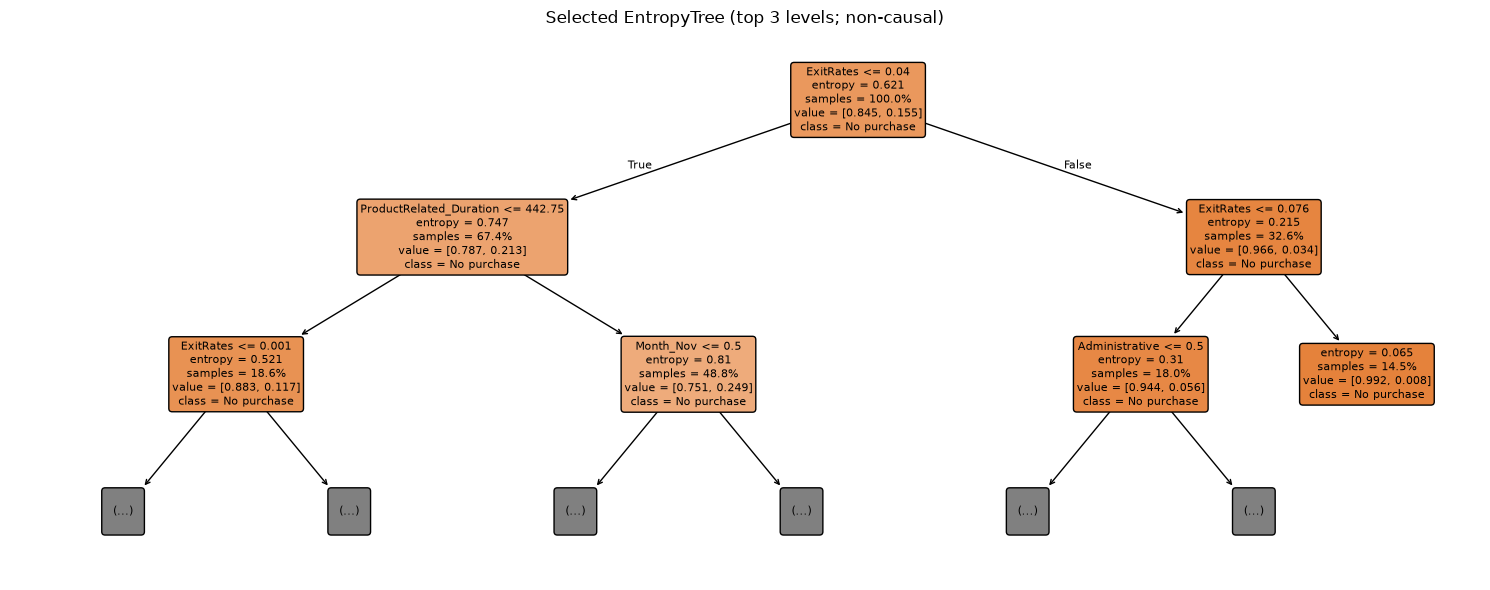

Tree: EntropyTree; root split ExitRates; alpha 0.00128706104; leaves 14; depth 6. Predictive associations, not causal effects.


In [18]:
# Tree-family explanation: show selected pruned Entropy BEFORE the overall winner is chosen.
illustrated_family='EntropyTree'  # Tree-family illustrative winner; not the overall classifier winner
illustrated=TREE_FITTED[illustrated_family]
tree_clf=illustrated.named_steps['clf']
encoded_features=illustrated.named_steps['pre'].get_feature_names_out()
fig,ax=plt.subplots(figsize=(15,6))
plot_tree(tree_clf,max_depth=2,feature_names=encoded_features,
    class_names=['No purchase','Purchase'],filled=True,rounded=True,
    proportion=True,fontsize=8,ax=ax)
ax.set_title(f'Selected {illustrated_family} (top 3 levels; non-causal)')
fig.tight_layout()
fig.savefig(V3_ART/'selected_tree_top_levels.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)
root_feature=int(tree_clf.tree_.feature[0])
root_name=str(encoded_features[root_feature]) if root_feature>=0 else 'single leaf'
print(f'Tree: {illustrated_family}; root split {root_name}; '
      f'alpha {TREE_SELECTED[illustrated_family]["ccp_alpha"]:.9g}; '
      f'leaves {tree_clf.get_n_leaves()}; depth {tree_clf.get_depth()}. '
      'Predictive associations, not causal effects.')


## 8. Six finalists and winner selection
**Purpose.** Select one predictive model without considering the hypothetical costs.

**Method.** Rank the four existing finalists and both selected tree specifications by **mean outer-fold ROC-AUC**; include AP and fold SD/SE as context. ROC overlays use pooled training OOF predictions for visualisation; the *mean of five AUCs*, not pooled AUC, determines the winner.

**Interpretation.** Small differences in mean AUC do not prove superiority. Sequential comparison may make CV performance optimistic.

,pathway,candidate,mean_auc,auc_sd,auc_se,mean_ap
0,Logit,L1 | Logit,0.75747,0.01361,0.00608,0.33623
1,EntropyTree,Selected | EntropyTree,0.74414,0.01214,0.00543,0.31300
2,BernoulliNB,B3 | BernoulliNB,0.74227,0.01564,0.00699,0.30158
3,LDA,Operational16 | LDA,0.74088,0.01277,0.00571,0.31649
4,GiniTree,Selected | GiniTree,0.73306,0.01363,0.00609,0.30389
5,GaussianNB,G7 | GaussianNB,0.71284,0.01895,0.00848,0.26793


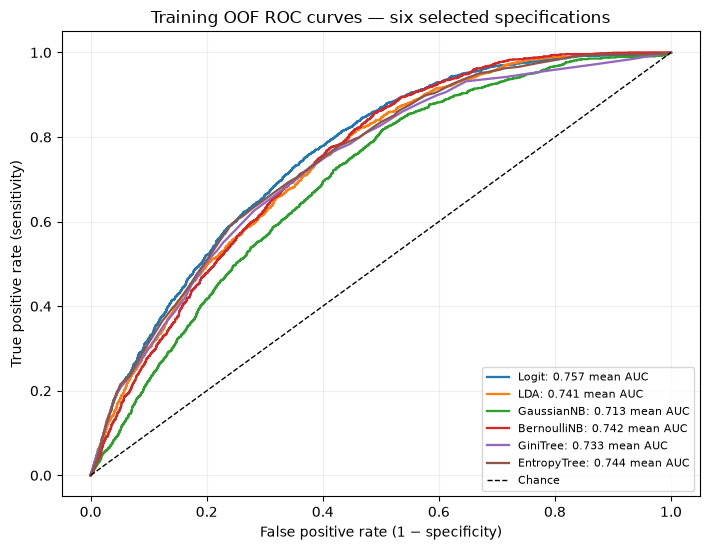

Winner: L1 | Logit | five-fold mean AUC 0.75747
Interpretation: winner AUC exceeds the runner-up by 0.0133; this descriptive gap does not establish significance or calibrated probabilities.
Both selected trees entered the six-way comparison directly.


In [17]:
FINALIST_FAMILIES=[*FAMILY_ORDER,*TREE_FAMILIES]
FINALIST_ROWS=[]
OOF_ROWS=[]
FOLD_SCORE_ROWS=[]
for fam in FINALIST_FAMILIES:
    label=PATH_FINALISTS[fam] if fam in PATH_FINALISTS else TREE_FINALISTS[fam]
    r=RESULTS[label]
    assert r['status']=='SCORED' and len(r['folds'])==K
    coverage=np.zeros(len(ytr),dtype=int)
    for (fit_idx,val_idx),fr in zip(FOLD_INDICES,r['folds']):
        coverage[val_idx]+=1
        yy=ytr.iloc[val_idx].to_numpy()
        pp=r['oof'][val_idx]
        assert abs(roc_auc_score(yy,pp)-fr['roc_auc'])<1e-12
        assert abs(average_precision_score(yy,pp)-fr['average_precision'])<1e-12
        FOLD_SCORE_ROWS.append({'family':fam,'finalist':label,'fold':fr['fold'],
                'roc_auc':fr['roc_auc'],'average_precision':fr['average_precision']})
    assert np.all(coverage==1)
    FINALIST_ROWS.append({'pathway':fam,'candidate':label,'mean_auc':r['mean_fold_auc'],
            'auc_sd':r['fold_auc_sd'],'auc_se':r['fold_auc_se'],
            'mean_ap':r['mean_fold_ap'],'pooled_oof_auc':r['pooled_oof_auc']})
    for row_id,yy,pp in zip(Xtr.index,ytr.to_numpy(),r['oof']):
        OOF_ROWS.append({'finalist':label,'row_id':int(row_id),'observed':int(yy),'oof_probability':float(pp)})
FINALISTS=pd.DataFrame(FINALIST_ROWS).sort_values(['mean_auc','candidate'],ascending=[False,True]).reset_index(drop=True)
WINNER_LABEL=str(FINALISTS.iloc[0]['candidate'])
WINNER_FAMILY=str(FINALISTS.iloc[0]['pathway'])
WINNER_CONFIG=(PATH_FINAL_CONFIGS[WINNER_FAMILY].copy()
    if WINNER_FAMILY in PATH_FINAL_CONFIGS else {'ccp_alpha':TREE_SELECTED[WINNER_FAMILY]['ccp_alpha']})
WINNER_OOF=np.asarray(RESULTS[WINNER_LABEL]['oof'],dtype=float)
BASE_RATE=float(ytr.mean())
FINALISTS.to_csv(V3_ART/'six_finalists.csv',index=False)
pd.DataFrame(FOLD_SCORE_ROWS).to_csv(V3_ART/'finalist_fold_scores.csv',index=False)
pd.DataFrame(OOF_ROWS).to_csv(V3_ART/'finalist_oof_scores.csv',index=False,float_format='%.17g')
display(FINALISTS[['pathway','candidate','mean_auc','auc_sd','auc_se','mean_ap']].round(5))
fig,ax=plt.subplots(figsize=(7.2,5.6))
for fam in FINALIST_FAMILIES:
    label=PATH_FINALISTS[fam] if fam in PATH_FINALISTS else TREE_FINALISTS[fam]
    fpr,tpr,_=roc_curve(ytr,RESULTS[label]['oof'])
    ax.plot(fpr,tpr,lw=1.65,label=f'{fam}: {RESULTS[label]["mean_fold_auc"]:.3f} mean AUC')
ax.plot([0,1],[0,1],'k--',lw=1,label='Chance')
ax.set(xlabel='False positive rate (1 − specificity)',ylabel='True positive rate (sensitivity)',
       title='Training OOF ROC curves — six selected specifications')
ax.legend(loc='lower right',fontsize=8)
ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(V3_ART/'six_finalists_roc.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)
print(f'Winner: {WINNER_LABEL} | five-fold mean AUC {float(FINALISTS.iloc[0]["mean_auc"]):.5f}')
print(f'Interpretation: winner AUC exceeds the runner-up by {float(FINALISTS.iloc[0].mean_auc-FINALISTS.iloc[1].mean_auc):.4f}; this descriptive gap does not establish significance or calibrated probabilities.')
assert len(FINALISTS)==6 and FINALISTS.pathway.nunique()==6
assert set(FINALISTS.pathway)==set(FINALIST_FAMILIES)
assert WINNER_LABEL not in {f'All17 | {f}' for f in FINALIST_FAMILIES}
print('Both selected trees entered the six-way comparison directly.')


## 9. Winner's training OOF scores and precision–recall behaviour
**Purpose.** See how buyer/nonbuyer scores overlap and whether minority-class detection is informative.

**Method.** Show one class-separated score histogram and one training OOF precision–recall curve, with the observed buyer prevalence as the no-skill reference. A simple reliability summary follows for the 0.20 decision assumption.

**Interpretation.** ROC-AUC/AP measure ordering, not well-calibrated probabilities. The financial cutoff is only decision-optimal under the stated assumptions *and* sufficiently calibrated probabilities.

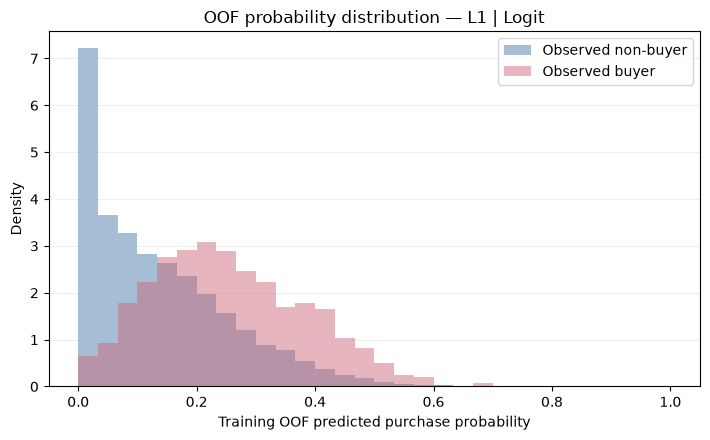

Nonbuyer OOF mean/median=0.1364/0.1088; buyer mean/median=0.2545/0.2415. Scores are below .50 for 99.2% of nonbuyers and 96.4% of buyers; at most 0.0% exceed .90 and the largest is 0.859. This score concentration makes predicted buyer counts sensitive to the chosen cutoff, but does not establish calibration.


In [19]:
fig,ax=plt.subplots(figsize=(7.2,4.5))
for cls,color,name in [(0,'#4477AA','Observed non-buyer'),(1,'#CC6677','Observed buyer')]:
    ax.hist(WINNER_OOF[np.asarray(ytr)==cls],bins=np.linspace(0,1,31),
            density=True,alpha=.48,color=color,label=name)
ax.set(xlabel='Training OOF predicted purchase probability',ylabel='Density',
       title=f'OOF probability distribution — {WINNER_LABEL}')
ax.legend(); ax.grid(axis='y',alpha=.2); fig.tight_layout()
fig.savefig(ARTIFACTS/'training_winner_oof_probability_histogram.png',dpi=180,bbox_inches='tight')
display(fig); plt.close(fig)
hist_rows=[]
for cls,name in [(0,'Observed non-buyer'),(1,'Observed buyer')]:
    values=WINNER_OOF[np.asarray(ytr)==cls]
    hist_rows.append({'observed_group':name,'sessions':len(values),'mean_probability':float(values.mean()),
      'median_probability':float(np.median(values)),'share_below_0.10':float(np.mean(values<.10)),
      'share_below_0.50':float(np.mean(values<.50)),'share_above_0.90':float(np.mean(values>.90)),
      'maximum_probability':float(values.max())})
WINNER_HIST_SUMMARY=pd.DataFrame(hist_rows)
hist_nonbuyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed non-buyer')].iloc[0]
hist_buyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed buyer')].iloc[0]
share_high=max(hist_nonbuyer['share_above_0.90'],hist_buyer['share_above_0.90'])
print(f"Nonbuyer OOF mean/median={hist_nonbuyer.mean_probability:.4f}/{hist_nonbuyer.median_probability:.4f}; buyer mean/median={hist_buyer.mean_probability:.4f}/{hist_buyer.median_probability:.4f}. Scores are below .50 for {hist_nonbuyer['share_below_0.50']:.1%} of nonbuyers and {hist_buyer['share_below_0.50']:.1%} of buyers; at most {share_high:.1%} exceed .90 and the largest is {max(hist_nonbuyer['maximum_probability'],hist_buyer['maximum_probability']):.3f}. This score concentration makes predicted buyer counts sensitive to the chosen cutoff, but does not establish calibration.")

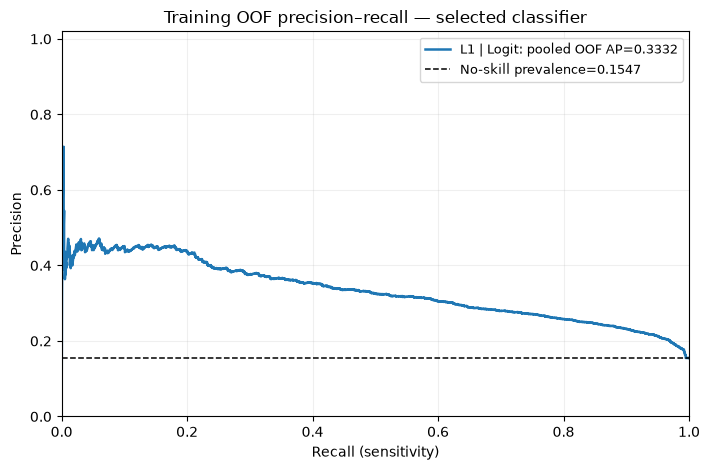

Mean fold AP=0.336226; pooled OOF AP=0.333169; prevalence=0.154704


In [20]:
# A10 — winner OOF precision–recall curve
precision_values,recall_values,_=precision_recall_curve(ytr,WINNER_OOF)
POOLED_AP=float(average_precision_score(ytr,WINNER_OOF))
BASE_RATE=float(ytr.mean())
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(recall_values,precision_values,lw=1.8,label=f'{WINNER_LABEL}: pooled OOF AP={POOLED_AP:.4f}')
ax.axhline(BASE_RATE,color='black',ls='--',lw=1.1,label=f'No-skill prevalence={BASE_RATE:.4f}')
ax.set(xlabel='Recall (sensitivity)',ylabel='Precision',xlim=(0,1),ylim=(0,1.02),
       title='Training OOF precision–recall — selected classifier')
ax.grid(alpha=.2);ax.legend(fontsize=9);fig.tight_layout()
fig.savefig(V3_ART/'winner_oof_pr.png',dpi=180,bbox_inches='tight')
display(fig);plt.close(fig)
print(f'Mean fold AP={float(FINALISTS.loc[FINALISTS.candidate.eq(WINNER_LABEL),"mean_ap"].iloc[0]):.6f}; pooled OOF AP={POOLED_AP:.6f}; prevalence={BASE_RATE:.6f}')


In [21]:
# Descriptive calibration check, no calibration model is fitted or chosen from holdout.
reliability=pd.DataFrame({'actual':ytr.to_numpy(),'predicted':WINNER_OOF})
reliability['bucket']=pd.cut(reliability.predicted,bins=np.linspace(0,1,11),include_lowest=True)
reliability=reliability.groupby('bucket',observed=True).agg(
    n=('actual','size'),observed_purchase_rate=('actual','mean'),mean_predicted_probability=('predicted','mean')).reset_index()
display(reliability.round(4))
reliability.to_csv(V3_ART/'winner_oof_reliability.csv',index=False)
near=reliability.loc[reliability['mean_predicted_probability'].between(.1,.3)]
print('Interpretation: OOF observed purchase frequency should be compared to mean predicted score around 0.20; upper score buckets are sparse, so probability quality is not established by AUC alone.')
display(near[['bucket','n','observed_purchase_rate','mean_predicted_probability']].round(4))

,bucket,n,observed_purchase_rate,mean_predicted_probability
0,"(-0.001, 0.1]",4106,0.0416,0.0383
1,"(0.1, 0.2]",2579,0.1559,0.1483
2,"(0.2, 0.3]",1748,0.2454,0.2447
3,"(0.3, 0.4]",908,0.3194,0.3448
4,"(0.4, 0.5]",402,0.4453,0.4421
5,"(0.5, 0.6]",103,0.4660,0.5396
6,"(0.6, 0.7]",16,0.4375,0.6349
7,"(0.7, 0.8]",1,0.0000,0.7633
8,"(0.8, 0.9]",1,0.0000,0.8593


Interpretation: OOF observed purchase frequency should be compared to mean predicted score around 0.20; upper score buckets are sparse, so probability quality is not established by AUC alone.


,bucket,n,observed_purchase_rate,mean_predicted_probability
1,"(0.1, 0.2]",2579,0.1559,0.1483
2,"(0.2, 0.3]",1748,0.2454,0.2447


## 10. Four threshold references
**Purpose.** Compare classification trade-offs with the hypothetical upselling decision.

**Method.** A prediction of Buy occurs if **p ≥ t**. Use the training buyer prevalence, 0.500, the nearest empirical sensitivity–specificity crossover, and the **fixed assumption-derived 0.200**. Here false positives mean contacting nonbuyers, whereas false negatives mean leaving actual buyers without upsell assistance.

**Payoffs (hypothetical, not observed).** S$3 per agent contact; conditional upsell probability 30% and incremental gross margin S$50. Expected net benefit of contacting an actual buyer = 0.3×50−3 = **S$12**; contacting a nonbuyer = **−S$3**. Thus relative error costs C_FP=3, C_FN=12, and t*=3/(3+12)=**0.20**. Equivalently, contact when 15p−3 > 0 (with equality classified Buy for reproducibility). These costs do not measure any intervention effect from UCI.

,reference,threshold,TP,FP,TN,FN,sensitivity,specificity,precision,hypothetical_relative_loss_SGD
0,Training prevalence,0.1547,1153,3113,5225,373,0.7556,0.6266,0.2703,13815
1,Conventional 0.500,0.5000,55,66,8272,1471,0.0360,0.9921,0.4545,17850
2,Sensitivity–specificity crossover,0.1795,1044,2634,5704,482,0.6841,0.6841,0.2838,13686
3,Cost-based (hypothetical),0.2000,953,2226,6112,573,0.6245,0.7330,0.2998,13554


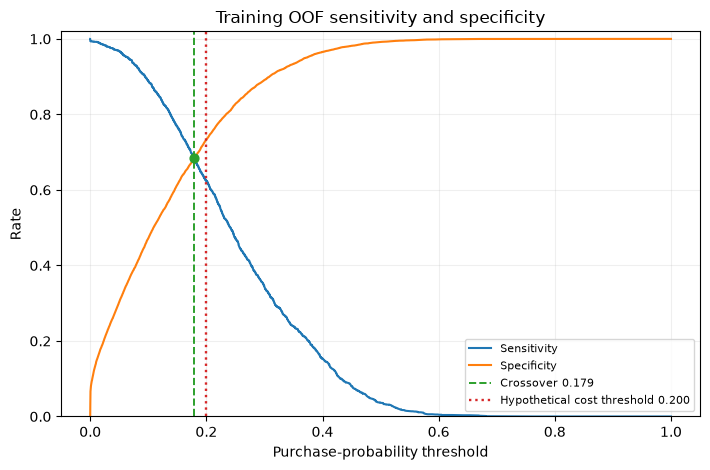

Financial threshold 0.20 is fixed independently of observed confusion matrices.
Interpretation: at 0.20, 953 buyers would be contacted and 2,226 nonbuyers contacted in training OOF predictions; this is a hypothetical cost trade-off, not observed upsell value.


In [22]:
def threshold_measures(y_true,prob,threshold):
    true=np.asarray(y_true,dtype=int)
    pred=(np.asarray(prob,dtype=float)>=float(threshold)).astype(int)
    tn,fp,fn,tp=confusion_matrix(true,pred,labels=[0,1]).ravel()
    return {'threshold':float(threshold),'TP':int(tp),'FP':int(fp),'TN':int(tn),'FN':int(fn),
            'sensitivity':float(tp/(tp+fn)),'specificity':float(tn/(tn+fp)),
            'precision':float(tp/(tp+fp)) if tp+fp else np.nan,
            'hypothetical_relative_loss_SGD':int(3*fp+12*fn)}
_,_,roc_candidates=roc_curve(ytr,WINNER_OOF,drop_intermediate=False)
cutoffs=np.unique(np.r_[roc_candidates[np.isfinite(roc_candidates)&(roc_candidates>=0)&(roc_candidates<=1)],0.,1.])
THRESHOLD_CURVE=pd.DataFrame([threshold_measures(ytr,WINNER_OOF,t) for t in cutoffs])
THRESHOLD_CURVE['gap']=(THRESHOLD_CURVE.sensitivity-THRESHOLD_CURVE.specificity).abs()
CROSSOVER=THRESHOLD_CURVE.sort_values(['gap','threshold'],kind='stable').iloc[0]
CROSSOVER_THRESHOLD=float(CROSSOVER.threshold)
THRESHOLD_REFS=[('Training prevalence',BASE_RATE),('Conventional 0.500',0.5),
                ('Sensitivity–specificity crossover',CROSSOVER_THRESHOLD),
                ('Cost-based (hypothetical)',0.2)]
THRESHOLD_TABLE=pd.DataFrame([{'reference':label,**threshold_measures(ytr,WINNER_OOF,t)}
                              for label,t in THRESHOLD_REFS])
assert len(THRESHOLD_TABLE)==4
assert THRESHOLD_TABLE[['TP','FP','TN','FN']].sum(axis=1).eq(len(ytr)).all()
assert np.isclose(THRESHOLD_TABLE.loc[3,'threshold'],0.2)
THRESHOLD_TABLE.to_csv(V3_ART/'four_threshold_references.csv',index=False)
THRESHOLD_CURVE.to_csv(V3_ART/'threshold_curves.csv',index=False)
display(THRESHOLD_TABLE.round(4))
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.sensitivity,label='Sensitivity')
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.specificity,label='Specificity')
ax.axvline(CROSSOVER_THRESHOLD,ls='--',color='tab:green',lw=1.4,label=f'Crossover {CROSSOVER_THRESHOLD:.3f}')
ax.axvline(0.2,ls=':',color='tab:red',lw=1.7,label='Hypothetical cost threshold 0.200')
ax.scatter([CROSSOVER_THRESHOLD],[float(CROSSOVER.sensitivity)],color='tab:green',s=40,zorder=5)
ax.set(xlabel='Purchase-probability threshold',ylabel='Rate',ylim=(0,1.02),
       title='Training OOF sensitivity and specificity')
ax.grid(alpha=.2);ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(V3_ART/'sensitivity_specificity.png',dpi=160,bbox_inches='tight')
display(fig);plt.close(fig)
print('Financial threshold 0.20 is fixed independently of observed confusion matrices.')
print(f'Interpretation: at 0.20, {int(THRESHOLD_TABLE.iloc[3].TP):,} buyers would be contacted and {int(THRESHOLD_TABLE.iloc[3].FP):,} nonbuyers contacted in training OOF predictions; this is a hypothetical cost trade-off, not observed upsell value.')

## 11. Cost-assumption sensitivity (no revenue simulation)
**Purpose.** Show how the hypothetical decision changes when the unknown upsell rate differs.

**Method.** Keep the S$3 contact cost and S$50 incremental gross margin fixed. Set conditional upsell success q=20%, 30% or 40%. Theoretical threshold t=s/(q×g), provided the assumed upsell benefit exceeds contact cost.

**Interpretation.** These are *input assumptions*, not estimated purchase uplift. The UCI data contain no agent assignments or upsell outcomes.

In [23]:
COST_SENSITIVITY=pd.DataFrame([{'assumed_upsell_success_q':q,'agent_cost_SGD':3.,
 'incremental_gross_margin_SGD':50.,'net_TP_value_SGD':q*50-3,
 'C_FP_SGD':3.,'C_FN_SGD':q*50-3.,
 'theoretical_probability_cutoff':3/(q*50)}
 for q in [.20,.30,.40]])
assert np.allclose(COST_SENSITIVITY.theoretical_probability_cutoff,[.30,.20,.15])
display(COST_SENSITIVITY.round(4))
COST_SENSITIVITY.to_csv(V3_ART/'upsell_sensitivity.csv',index=False)

,assumed_upsell_success_q,agent_cost_SGD,incremental_gross_margin_SGD,net_TP_value_SGD,C_FP_SGD,C_FN_SGD,theoretical_probability_cutoff
0,0.2,3.0,50.0,7.0,3.0,7.0,0.30
1,0.3,3.0,50.0,12.0,3.0,12.0,0.20
2,0.4,3.0,50.0,17.0,3.0,17.0,0.15


## 12. Historically frozen reserved check and final fit (original v3.4 computation)

**Purpose.** Show the original v3.4 post-selection reserved check and full-data refit. These outcomes are **not recomputed as part of the v3.5 presentation**.

**Historical method.** v3.4 refitted the already selected winner to 9,864 training sessions, checked the 2,466 reserved observations and refitted the same recipe to all 12,330 rows. The historical reserved set was examined during earlier versions; it is **not pristine**. No model change is made in v3.5.

In [24]:
# Independent recomputation of *every* attempted CV fold from the saved OOF vectors.
# This checks correctness, not a second feature search, and uses no reserved outcomes.
def independently_audit_training_results():
    audits=[]
    known_labels=list(RESULTS)
    assert len(known_labels)==51, f'Expected 51 specs, including 41 trial records, diagnostics and selected trees; found {len(known_labels)}'
    excluded=(set(f'All17 | {f}' for f in FINALIST_FAMILIES)
       | set(f'Operational16 | {f}' for f in TREE_FAMILIES)
       | set(TREE_FINALISTS.values()))
    assert set(ATTEMPTS_DF.candidate)==set(known_labels)-excluded
    for name,res in RESULTS.items():
        p=np.asarray(res['oof'],dtype=float)
        assert p.shape==(len(ytr),) and np.isfinite(p).all()
        fold_aucs=[];fold_aps=[]
        for (fit_idx,val_idx),record in zip(FOLD_INDICES,res['folds']):
            assert record['fit_status']=='OK'
            yy=ytr.iloc[val_idx].to_numpy()
            auc=float(roc_auc_score(yy,p[val_idx]))
            ap=float(average_precision_score(yy,p[val_idx]))
            assert np.isclose(auc,record['roc_auc'],atol=1e-12,rtol=0)
            assert np.isclose(ap,record['average_precision'],atol=1e-12,rtol=0)
            fold_aucs.append(auc);fold_aps.append(ap)
        avg=float(np.mean(fold_aucs))
        sd=float(np.std(fold_aucs,ddof=1))
        se=float(sd/np.sqrt(K))
        assert np.isclose(avg,res['mean_fold_auc'],atol=1e-12,rtol=0)
        assert np.isclose(sd,res['fold_auc_sd'],atol=1e-12,rtol=0)
        assert np.isclose(se,res['fold_auc_se'],atol=1e-12,rtol=0)
        assert np.isclose(np.mean(fold_aps),res['mean_fold_ap'],atol=1e-12,rtol=0)
        audits.append({'candidate':name,'folds_verified':len(fold_aucs),'mean_auc':avg,'auc_sd':sd,'auc_se':se})
    for _,trial in ATTEMPTS_DF.iterrows():
        if trial.step in ('L0','D0','G0','B0'):
            continue
        challenger=RESULTS[trial.candidate]
        parent=RESULTS[trial.parent]
        delta=challenger['mean_fold_auc']-parent['mean_fold_auc']
        assert np.isclose(delta,trial.delta_auc,atol=1e-12,rtol=0)
        assert bool(delta>challenger['fold_auc_se'])==bool(trial.accepted)
    extras=ATTEMPTS_DF.loc[ATTEMPTS_DF.trial_version.eq('v3.2')]
    assert len(extras)==11
    assert set(extras.step)=={'L5','L6','L7','D5','D6','D7','G5','G6','G7','G8','G9'}
    for family in FAMILY_ORDER:
        group=extras.loc[extras.pathway.eq(family)]
        anchor=V31_PATH_FINALISTS[family]
        assert group.parent.eq(anchor).all()
        eligible=group.loc[group.accepted]
        expected=(eligible.sort_values(['mean_auc','step'],ascending=[False,True]).iloc[0].candidate
                  if len(eligible) else anchor)
        assert V32_PATH_FINALISTS[family]==expected
        assert V32_PROBE_SELECTION[family]['selected']==expected
        assert set(V32_PROBE_SELECTION[family]['qualified'])==set(eligible.candidate)
    additions=ATTEMPTS_DF.loc[ATTEMPTS_DF.trial_version.eq('v3.3')]
    assert len(additions)==7
    assert set(additions.step)=={'L8','L9','L10','D8','D9','D10','D11'}
    for family in FAMILY_ORDER:
        group=additions.loc[additions.pathway.eq(family)]
        anchor=V32_PATH_FINALISTS[family]
        assert group.parent.eq(anchor).all()
        eligible=group.loc[group.accepted]
        expected=(eligible.sort_values(['mean_auc','step'],ascending=[False,True]).iloc[0].candidate
                  if len(eligible) else anchor)
        assert V33_PATH_FINALISTS[family]==expected
        assert V33_PROBE_SELECTION[family]['selected']==expected
        assert set(V33_PROBE_SELECTION[family]['qualified'])==set(eligible.candidate)
    new34=ATTEMPTS_DF.loc[ATTEMPTS_DF.trial_version.eq('v3.4')]
    assert len(new34)==3 and set(new34.step)=={'L13','L14','D15'}
    for fam in FAMILY_ORDER:
        added=new34.loc[new34.pathway.eq(fam)]
        anchor=V33_PATH_FINALISTS[fam]
        retained=anchor
        for t in added.itertuples():
            assert t.parent==retained
            if t.accepted:
                retained=t.candidate
        assert PATH_FINALISTS[fam]==retained
        assert V34_PROBE_SELECTION[fam]['anchor']==anchor
        assert V34_PROBE_SELECTION[fam]['selected']==retained
    assert all(RESULTS['D15 | LDA']['folds'][f-1]['selected_source_count'] in range(1,17)
               for f in range(1,K+1))
    assert len(BACKWARD_PATH_ROWS)==K*16
    for f in range(1,K+1):
        path=[p for p in BACKWARD_PATH_ROWS if p['outer_fold']==f]
        assert set(p['source_count'] for p in path)==set(range(1,17))
        assert sum(bool(p['is_selected']) for p in path)==1
        best=max(path,key=lambda x:x['inner_mean_auc'])
        cutoff=best['inner_mean_auc']-best['inner_auc_se']
        elig=[p for p in path if p['inner_mean_auc']>=cutoff-1e-14]
        chosen=next(p for p in path if p['is_selected'])
        assert chosen['source_count']==min(p['source_count'] for p in elig)
    for t in new34.itertuples():
        if t.pathway=='Logit':
            assert t.new_change.find("'scale': True")>=0
            assert ('lasso' in t.new_change if t.step=='L13' else 'elasticnet' in t.new_change)
    for _,row in THRESHOLD_TABLE.iterrows():
        counted=threshold_measures(ytr,WINNER_OOF,float(row.threshold))
        for key in ('TP','FP','TN','FN'):
            assert counted[key]==int(row[key])
        assert sum(counted[k] for k in ('TP','FP','TN','FN'))==len(ytr)
        for key in ('sensitivity','specificity','precision'):
            assert np.isclose(counted[key],row[key],atol=1e-12,rtol=0)
    assert len(FINALISTS)==6 and FINALISTS.mean_auc.iloc[0]==FINALISTS.mean_auc.max()
    assert WINNER_LABEL==FINALISTS.iloc[0].candidate
    # Independently audit every pruning candidate against stored fold scores.
    tree_verified=0; tree_folds_verified=0
    for family in TREE_FAMILIES:
        path=TREE_PATH.loc[TREE_PATH.family.eq(family)].copy()
        recorded=TREE_FOLDS.loc[TREE_FOLDS.family.eq(family)]
        assert len(recorded)==K*len(path)
        for _,candidate in path.iterrows():
            score=recorded.loc[recorded.ccp_alpha.eq(candidate.ccp_alpha)]
            assert len(score)==K and set(score.fold)==set(range(1,K+1))
            auc=score.roc_auc.to_numpy(float); ap=score.average_precision.to_numpy(float)
            assert np.isclose(auc.mean(),candidate.mean_auc,atol=1e-12,rtol=0)
            assert np.isclose(auc.std(ddof=1),candidate.auc_sd,atol=1e-12,rtol=0)
            assert np.isclose(auc.std(ddof=1)/np.sqrt(K),candidate.auc_se,atol=1e-12,rtol=0)
            assert np.isclose(ap.mean(),candidate.mean_ap,atol=1e-12,rtol=0)
            tree_verified+=1;tree_folds_verified+=K
        best=path.sort_values(['mean_auc','ccp_alpha'],ascending=[False,True]).iloc[0]
        cutoff=float(best.mean_auc-best.auc_se)
        good=path.loc[path.mean_auc.ge(cutoff-1e-14)].copy()
        selected=good.sort_values(['leaves','mean_auc','ccp_alpha'],
            ascending=[True,False,True]).iloc[0]
        assert path.selected.sum()==1 and np.isclose(float(selected.ccp_alpha),
            TREE_SELECTED[family]['ccp_alpha'],atol=1e-16,rtol=0)
        assert np.isclose(cutoff,TREE_SELECTED[family]['one_se_cutoff'],atol=1e-12,rtol=0)
        assert int(selected.leaves)==TREE_SELECTED[family]['leaves']
        assert set(path.loc[path.eligible].ccp_alpha)==set(good.ccp_alpha)
        assert len(path)==TREE_SELECTED[family]['total_candidates']
        a=RESULTS[f'All17 | {family}']; b=RESULTS[f'Operational16 | {family}']
        assert len(a['folds'])==len(b['folds'])==K
        for key in ('mean_fold_auc','mean_fold_ap'):
            assert np.isfinite(a[key]) and np.isfinite(b[key])
        assert TREE_FINALISTS[family] in set(FINALISTS.candidate)
    return {'status':'PASS','cv_candidates_verified':len(audits),
            'individual_fold_scores_verified':sum(q['folds_verified'] for q in audits),
            'tree_alpha_candidates_verified':tree_verified,'tree_alpha_folds_verified':tree_folds_verified,
            'six_all17':len(ALL17),'six_operational_baselines':len(OP16),
            'sequential_decisions_verified':len(ATTEMPTS_DF)-4,
            'legacy_decisions_verified':16,'new_anchored_probes_verified':11,
            'v33_anchored_probes_verified':7,
            'v34_sequential_probes_verified':3,
            'backward_lda_path_entries_verified':len(BACKWARD_PATH_ROWS),
            'threshold_rows_verified':len(THRESHOLD_TABLE),
            'winner':WINNER_LABEL,'test_data_used_in_verification':False}
TRAINING_AUDIT=independently_audit_training_results()
with (V3_ART/'independent_training_audit.json').open('w') as f:
    json.dump(TRAINING_AUDIT,f,indent=2,allow_nan=False)
print('Independent training evidence audit:',TRAINING_AUDIT)

def validate_fitted_model(model,X,description):
    actual=model.best_estimator_ if isinstance(model,GridSearchCV) else model
    estimator=actual.named_steps['clf']
    numbers=[np.asarray(getattr(estimator,k),dtype=float)
        for k in ('coef_','intercept_','theta_','var_','class_prior_','feature_log_prob_','means_','priors_')
        if hasattr(estimator,k)]
    if isinstance(estimator,DecisionTreeClassifier):
        numbers=[np.asarray(estimator.tree_.impurity,float),
                 np.asarray(estimator.tree_.value,float),
                 np.asarray(estimator.tree_.threshold[estimator.tree_.feature>=0],float)]
    if not numbers or not all(np.isfinite(a).all() for a in numbers):
        raise RuntimeError(f'{description}: finite parameter audit failed')
    sample=model.predict_proba(X)[:,1]
    if not np.isfinite(sample).all() or ((sample<0)|(sample>1)).any():
        raise RuntimeError(f'{description}: invalid probability output')
    design=actual.named_steps['pre'].transform(X)
    n_cols=int(design.shape[1])
    rank=int(np.linalg.matrix_rank(design[:min(3000,len(design))]))
    max_coef=(float(np.max(np.abs(estimator.coef_))) if hasattr(estimator,'coef_') else None)
    return {'description':description,'finite_parameters':True,
            'encoded_columns':n_cols,'sample_design_rank':rank,
            'max_absolute_coefficient':max_coef,
            'probability_min':float(sample.min()),'probability_max':float(sample.max()),
            'chosen_inner_CV_params':model.best_params_ if isinstance(model,GridSearchCV) else {}}

SELECTED_TRAIN_MODEL=(tree_pipeline(WINNER_FAMILY,WINNER_CONFIG['ccp_alpha'],SAFE)
    if WINNER_FAMILY in TREE_FAMILIES else build_model(WINNER_FAMILY,WINNER_CONFIG,SAFE))
with warnings.catch_warnings(record=True) as train_warnings:
    warnings.simplefilter('always')
    SELECTED_TRAIN_MODEL.fit(Xtr[SAFE],ytr)
TRAIN_AUDIT=validate_fitted_model(SELECTED_TRAIN_MODEL,Xtr[SAFE],'Frozen training fit')
if any(issubclass(w.category,ConvergenceWarning) for w in train_warnings):
    raise RuntimeError('Frozen training fit convergence warning; inspect before external claims')
print('Frozen training fit passed parameter and probability checks.')

# Do not access any holdout outcome until the winner, four thresholds and training refit
# are fully frozen above. The source is re-read, avoiding any earlier holdout exposure.
reserved=pd.read_csv(data_path)
reserved.insert(0,'_row_id',np.arange(len(reserved),dtype=int))
reserved=reserved.set_index('_row_id').loc[test_ids]
X_test=reserved[SAFE].copy()
X_test[CAT]=X_test[CAT].astype('string')
X_test['Weekend']=X_test['Weekend'].astype(int)
y_test=reserved[TARGET].astype(int)
del reserved
assert len(X_test)==2466 and len(y_test)==2466
test_prob=np.asarray(SELECTED_TRAIN_MODEL.predict_proba(X_test)[:,1],dtype=float)
TEST_AUDIT={'n_test':int(len(y_test)),
   'roc_auc':float(roc_auc_score(y_test,test_prob)),
   'average_precision':float(average_precision_score(y_test,test_prob)),
   'cost_threshold_0_20':threshold_measures(y_test,test_prob,.20)}
display(pd.DataFrame([{'sample':'Reserved v3.4 check (historically previously used)',
            'n':TEST_AUDIT['n_test'],'ROC-AUC':TEST_AUDIT['roc_auc'],
            'AP':TEST_AUDIT['average_precision'],**TEST_AUDIT['cost_threshold_0_20']}]).round(4))
print('This v3.4 holdout was examined once AFTER freezing the training selection. Prior historical reuse prevents a pristine-independent-test claim.')

# Final all-data refit uses the same selected pathway recipe, no new model selection.
all_rows=pd.read_csv(data_path)
assert len(all_rows)==12330 and set(all_rows.columns)==EXPECTED
all_rows[CAT]=all_rows[CAT].astype('string')
all_rows['Weekend']=all_rows['Weekend'].astype(int)
FINAL_PIPELINE=(tree_pipeline(WINNER_FAMILY,WINNER_CONFIG['ccp_alpha'],SAFE)
    if WINNER_FAMILY in TREE_FAMILIES else build_model(WINNER_FAMILY,WINNER_CONFIG,SAFE))
with warnings.catch_warnings(record=True) as final_warnings:
    warnings.simplefilter('always')
    FINAL_PIPELINE.fit(all_rows[SAFE],all_rows[TARGET].astype(int))
FINAL_AUDIT=validate_fitted_model(FINAL_PIPELINE,all_rows[SAFE],'Final all-data refit')
if any(issubclass(w.category,ConvergenceWarning) for w in final_warnings):
    raise RuntimeError('Final full-data refit convergence warning; inspect before external claims')

RUN_METADATA={'prd':'v3.4','data_sha256':source_hash,
 'random_state':SEED,'training_rows':len(ytr),'test_rows':len(y_test),
 'final_rows':len(all_rows),'cv_folds':K,'inner_folds':INNER_FOLDS,
 'selected_model':WINNER_LABEL,'selected_family':WINNER_FAMILY,
 'selected_recipe':WINNER_CONFIG,'four_original_path_finalists':V31_PATH_FINALISTS,
 'updated_v32_path_finalists':V32_PATH_FINALISTS,
 'v32_anchored_probe_selection':V32_PROBE_SELECTION,
 'updated_v33_path_finalists':V33_PATH_FINALISTS,
 'v33_anchored_probe_selection':V33_PROBE_SELECTION,
 'updated_v34_path_finalists':PATH_FINALISTS,
 'v34_sequential_probe_selection':V34_PROBE_SELECTION,
 'six_finalists':FINALISTS.candidate.tolist(),'tree_selection':TREE_SELECTED,
 'test_check':TEST_AUDIT,'train_fit_audit':TRAIN_AUDIT,'final_fit_audit':FINAL_AUDIT,
 'train_warnings':[str(w.message) for w in train_warnings],
 'final_warnings':[str(w.message) for w in final_warnings],
 'historically_pristine_holdout':False,
 'training_evidence_audit':TRAINING_AUDIT,
 'd15_outer_selected_sources':[
   {'fold':int(fr['fold']),'source_count':int(fr['selected_source_count']),
    'sources':json.loads(fr['selected_source_cols'])} for fr in RESULTS['D15 | LDA']['folds']],
 'versions':{'python':platform.python_version(),'pandas':pd.__version__,
            'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__}}
with (V3_ART/'run_metadata.json').open('w') as f:
    json.dump(RUN_METADATA,f,indent=2,allow_nan=False,default=str)
pd.DataFrame(FOLD_ROWS).to_csv(V3_ART/'all_attempt_fold_scores.csv',index=False)
pd.DataFrame(WARNING_ROWS).to_csv(V3_ART/'fit_warnings.csv',index=False)
pd.DataFrame({'row_id':Xtr.index,'observed':ytr.to_numpy(),
              'winner_oof_probability':WINNER_OOF}).to_csv(V3_ART/'winner_oof.csv',index=False)
pd.DataFrame({'row_id':test_ids,'observed':y_test.to_numpy(),
              'test_probability':test_prob}).to_csv(V3_ART/'frozen_holdout_scores.csv',index=False)
print('Final all-data fit verified for:',WINNER_LABEL)
print('Interpretation: reserved-set ROC-AUC is a version-specific check, not independent of earlier project exploration; no specifications were revised after seeing this result.')
with (V3_ART/'final_specification.json').open('w') as out:
    json.dump({'winner':WINNER_LABEL,'family':WINNER_FAMILY,
       'configuration':WINNER_CONFIG,'test_evaluated_only_after_training_freeze':True},
       out,indent=2,allow_nan=False)
pd.DataFrame({'row_id':train_ids,'partition':'train'}).to_csv(V3_ART/'train_row_ids.csv',index=False)
pd.DataFrame({'row_id':test_ids,'partition':'test'}).to_csv(V3_ART/'test_row_ids.csv',index=False)
pd.DataFrame(fold_map).to_csv(V3_ART/'cv_fold_row_ids.csv',index=False)


Independent training evidence audit: {'status': 'PASS', 'cv_candidates_verified': 51, 'individual_fold_scores_verified': 255, 'tree_alpha_candidates_verified': 722, 'tree_alpha_folds_verified': 3610, 'six_all17': 6, 'six_operational_baselines': 6, 'sequential_decisions_verified': 37, 'legacy_decisions_verified': 16, 'new_anchored_probes_verified': 11, 'v33_anchored_probes_verified': 7, 'v34_sequential_probes_verified': 3, 'backward_lda_path_entries_verified': 80, 'threshold_rows_verified': 4, 'winner': 'L1 | Logit', 'test_data_used_in_verification': False}


Frozen training fit passed parameter and probability checks.


,sample,n,ROC-AUC,AP,threshold,TP,FP,TN,FN,sensitivity,specificity,precision,hypothetical_relative_loss_SGD
0,Reserved v3.4 check (historically previously u...,2466,0.7405,0.3272,0.2,237,569,1515,145,0.6204,0.727,0.294,3447


This v3.4 holdout was examined once AFTER freezing the training selection. Prior historical reuse prevents a pristine-independent-test claim.


Final all-data fit verified for: L1 | Logit
Interpretation: reserved-set ROC-AUC is a version-specific check, not independent of earlier project exploration; no specifications were revised after seeing this result.


## 13. Final findings, interpretation and limitations

**Winner.** L1 Logistic Regression remains the retained model with **mean training five-fold ROC-AUC 0.75747**, ahead of the entropy tree (0.74414), Bernoulli NB (0.74227), LDA (0.74088), Gini tree (0.73306) and Gaussian NB (0.71284).

**What the experiments establish.** Only a modest Logit log1p activity transformation qualified against its baseline. More complicated shrinkage, nonlinear transformations and stepwise feature selection did **not** yield sufficiently large gains under the historical one-SE heuristic. Some unaccepted trials achieved numerically higher mean AUC; this is not a contradiction. G6 and G7 both qualified against G0, with G7 becoming the Gaussian NB finalist.

**Limitations.** (i) Prediction, **not causal or confirmatory inference**; no observed agent/upsell response. (ii) ROC-AUC and AP do **not** establish calibration or economics at threshold 0.20. (iii) Gaussian marginals/Naive Bayes independence and LDA pooled covariance are model approximations; Logit requires an adequate functional form. (iv) Rare categorical levels, duplicated observations and ambiguous feature availability limit deployment interpretation. (v) Post-hoc selection among numerous probes on reused folds can introduce optimism. (vi) The historically consulted reserved set is not a new independent test. (vii) The 26-trial v3.5 shortlist is **post-hoc editorial curation** of an unchanged 41-trial history, not a newly preregistered selection exercise.

**Evidence:** [PRD v3.5](PRD_v3.5.md), [full trials](artifacts/prd_v3_4/all_attempts_ledger.csv), [full pruning paths](artifacts/prd_v3_4/tree_alpha_paths.csv) and [independent v3.4 PASS audit](artifacts/prd_v3_4/independent_training_audit.json).

In [25]:
row=FINALISTS.iloc[0]
business=THRESHOLD_TABLE.loc[THRESHOLD_TABLE.reference.eq('Cost-based (hypothetical)')].iloc[0]
print('PRD 3.5 PRESENTATION SUMMARY — frozen v3.4 computations')
print(f"Six pathway finalists: {FINALISTS.candidate.tolist()}")
print(f"Winner: {WINNER_LABEL}; mean five-fold ROC-AUC={row.mean_auc:.5f} (SD={row.auc_sd:.5f}; SE={row.auc_se:.5f}); mean AP={row.mean_ap:.5f}.")
print(f"Training buyer prevalence: {BASE_RATE:.4f}; OOF pooled AP: {average_precision_score(ytr,WINNER_OOF):.5f}.")
print(f"Fixed cost cutoff 0.200: TP={int(business.TP)}, FP={int(business.FP)}, TN={int(business.TN)}, FN={int(business.FN)}, sensitivity={business.sensitivity:.4f}, specificity={business.specificity:.4f}, precision={business.precision:.4f}.")
print(f"Reserved v3.4 check: ROC-AUC={TEST_AUDIT['roc_auc']:.5f}; AP={TEST_AUDIT['average_precision']:.5f} (historical prior use caveat).")
print("Historical evidence preserved: 20 v3.1 + 11 v3.2 + 7 v3.3 + 3 v3.4 = 41 original-family trials; main v3.5 view displays 26.")
print('Do not interpret illustrative upsell threshold as causal uplift, calibrated economic optimality, or deployment approval.')
print('Selected Gini/Entropy:',TREE_SELECTED)
print('Six all-17 diagnostics, six operational baselines, four tree stages and six finalists are separate from the 26 curated trials.')


PRD 3.5 PRESENTATION SUMMARY — frozen v3.4 computations
Six pathway finalists: ['L1 | Logit', 'Selected | EntropyTree', 'B3 | BernoulliNB', 'Operational16 | LDA', 'Selected | GiniTree', 'G7 | GaussianNB']
Winner: L1 | Logit; mean five-fold ROC-AUC=0.75747 (SD=0.01361; SE=0.00608); mean AP=0.33623.
Training buyer prevalence: 0.1547; OOF pooled AP: 0.33317.
Fixed cost cutoff 0.200: TP=953, FP=2226, TN=6112, FN=573, sensitivity=0.6245, specificity=0.7330, precision=0.2998.
Reserved v3.4 check: ROC-AUC=0.74054; AP=0.32720 (historical prior use caveat).
Historical evidence preserved: 20 v3.1 + 11 v3.2 + 7 v3.3 + 3 v3.4 = 41 original-family trials; main v3.5 view displays 26.
Do not interpret illustrative upsell threshold as causal uplift, calibrated economic optimality, or deployment approval.
Selected Gini/Entropy: {'GiniTree': {'criterion': 'gini', 'ccp_alpha': 0.0010076415207989561, 'depth': 4, 'leaves': 8, 'mean_auc': 0.7330553881106839, 'mean_ap': 0.30389436712475826, 'best_mean_auc': 